# Análisis exploratorio de datos: Predict Future Sales

Este notebook explora las ventas diarias históricas de la cadena de tiendas rusa 1C Company (dataset *Predict Future Sales* de Kaggle). El objetivo es entender la estructura, la calidad y el comportamiento temporal de los datos antes de construir un modelo que pronostique las ventas mensuales (`item_cnt_month`) de cada par tienda-producto para noviembre de 2015.

Las secciones siguen el orden del enunciado del Proyecto 1; cada título indica entre paréntesis el punto del enunciado que responde. Las decisiones de limpieza y los parámetros del análisis están en el archivo de configuración `pipeline_config.yaml`, en la raíz del proyecto.

## 1. Librerías y configuración

Se cargan las librerías que se usarán en el análisis:

- **pandas** y **numpy**: manejo de tablas y cálculos numéricos.
- **matplotlib** y **seaborn**: gráficas.
- **statsmodels**: herramientas de series de tiempo (descomposición, ACF y PACF).
- **yaml**: lectura del archivo de configuración del proyecto.

También se define un estilo uniforme para las gráficas y el formato con que pandas muestra los números.

In [1]:
# --- Librerías estándar de Python ---
import os  # leer variables de entorno (por ejemplo DATA_DIR)
from pathlib import Path  # manejar rutas de archivos de forma independiente del sistema operativo

# --- Análisis de datos ---
import numpy as np  # cálculos numéricos
import pandas as pd  # tablas de datos (DataFrames)
import yaml  # lectura del archivo de configuración pipeline_config.yaml

# --- Visualización ---
import matplotlib.pyplot as plt  # gráficas base
import matplotlib.ticker as mticker  # formato de los números en los ejes
import seaborn as sns  # gráficas estadísticas con mejor estilo

# --- Series de tiempo ---
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # gráficos de autocorrelación
from statsmodels.tsa.seasonal import seasonal_decompose  # separa tendencia, estacionalidad y residuo
from statsmodels.tsa.stattools import acf, pacf  # valores numéricos de ACF y PACF

%matplotlib inline
sns.set_theme(style="whitegrid")  # estilo visual uniforme para todas las gráficas
pd.set_option("display.max_columns", None)  # mostrar todas las columnas de las tablas
pd.set_option("display.float_format", "{:,.2f}".format)  # decimales con separador de miles

# Formateador de ejes: muestra los números grandes con separador de miles (1,000,000)
MILES = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

## 2. Carga de datos (2a)

Se leen los cinco archivos del dataset. Las rutas no están fijas en el código, para que el notebook funcione en cualquier computadora:

- La raíz del proyecto se detecta buscando el archivo `pyproject.toml`.
- La configuración (nombres de archivos, decisiones de limpieza y parámetros) se lee de `pipeline_config.yaml`.
- La carpeta de datos es `data/raw/` por defecto; para usar otra basta con definir la variable de entorno `DATA_DIR`.

`sales_train.csv` tiene cerca de 2.9 millones de filas, por eso se cargan sus columnas con tipos numéricos compactos (`int8`, `int32`, `float32`), que ocupan menos memoria. La columna `date` se deja como texto en este paso; su conversión se valida en la sección 8.

In [2]:
# Raíz del proyecto: primera carpeta (desde la actual hacia arriba) que contenga pyproject.toml
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

# Lectura de la configuración compartida del proyecto
with open(PROJECT_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    CONFIG = yaml.safe_load(f)

# Carpeta de datos: la variable de entorno DATA_DIR tiene prioridad; si no existe se usa data/raw
DATA_DIR = Path(os.getenv("DATA_DIR", PROJECT_ROOT / CONFIG["data"]["raw_dir"]))
FILES = CONFIG["data"]["files"]  # nombres de los archivos CSV

# Tipos compactos para las columnas numéricas de sales_train (ahorran memoria)
SALES_DTYPES = {
    "date_block_num": "int8",  # mes consecutivo 0-33: cabe en 1 byte
    "shop_id": "int8",  # 60 tiendas: cabe en 1 byte
    "item_id": "int32",  # ~22 mil productos
    "item_price": "float32",  # precio unitario
    "item_cnt_day": "float32",  # unidades vendidas en el día
}

# Carga de cada archivo en un DataFrame
sales_raw = pd.read_csv(DATA_DIR / FILES["sales"], dtype=SALES_DTYPES)  # ventas diarias (train)
items = pd.read_csv(DATA_DIR / FILES["items"])  # catálogo de productos
categories = pd.read_csv(DATA_DIR / FILES["categories"])  # catálogo de categorías
shops = pd.read_csv(DATA_DIR / FILES["shops"])  # catálogo de tiendas
test = pd.read_csv(DATA_DIR / FILES["test"])  # pares tienda-producto a predecir

# Se muestra la carpeta de datos de forma relativa a la raíz (sin exponer rutas del equipo)
try:
    print("Carpeta de datos:", DATA_DIR.relative_to(PROJECT_ROOT))
except ValueError:  # DATA_DIR está fuera del proyecto: solo se muestra su nombre
    print("Carpeta de datos (externa):", DATA_DIR.name)

Carpeta de datos: data\raw


## 3. Primeras filas de cada tabla (2a)

Se muestran las primeras cinco filas de cada archivo para ver cómo vienen los datos. Los nombres de productos, categorías y tiendas están en ruso.

In [3]:
# Diccionario con las cinco tablas para recorrerlas con un mismo bloque de código
TABLAS = {"sales_train": sales_raw, "items": items, "item_categories": categories, "shops": shops, "test": test}

# Se imprime el nombre de cada tabla y sus 5 primeras filas
for nombre, df in TABLAS.items():
    print(f"\n=== {nombre} ===")
    display(df.head())


=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00



=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40



=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4



=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4



=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


## 4. Tamaño de cada tabla (2b)

Número de filas y columnas de cada archivo, y la memoria que ocupa en el equipo.

In [4]:
# Tabla resumen: filas, columnas y memoria (MB) de cada archivo cargado
tamanos = pd.DataFrame({
    "filas": {n: df.shape[0] for n, df in TABLAS.items()},  # número de registros
    "columnas": {n: df.shape[1] for n, df in TABLAS.items()},  # número de variables
    "memoria_MB": {n: df.memory_usage(deep=True).sum() / 1024**2 for n, df in TABLAS.items()},  # memoria en MB
})
tamanos

,filas,columnas,memoria_MB
sales_train,2935849,6,226.79
items,22170,3,3.66
item_categories,84,2,0.01
shops,60,2,0.01
test,214200,3,4.90


**Interpretación.** `sales_train` es la tabla principal: 2,935,849 transacciones diarias en 6 columnas (unos 227 MB en memoria aun con tipos compactos). Los catálogos son pequeños: 22,170 productos, 84 categorías y 60 tiendas. `test` tiene 214,200 pares tienda-producto a predecir. El volumen de `sales_train` obliga a trabajar con agregaciones (por día, mes, tienda o producto) en lugar de graficar las filas individuales.

## 5. Descripción de las columnas y variable objetivo (2c)

| Columna | Tabla | Qué representa |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto `dd.mm.aaaa` en el archivo original). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, …, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador único de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador único del producto. |
| `item_price` | sales_train | Precio unitario del producto en esa transacción (rublos). |
| `item_cnt_day` | sales_train | Unidades vendidas ese día; los valores negativos son devoluciones. |
| `item_name` | items | Nombre del producto. |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría. |
| `shop_name` | shops | Nombre de la tienda (ciudad y centro comercial). |
| `ID` | test | Identificador de cada fila a predecir. |

**Variable objetivo.** La competencia no pide predecir ventas diarias sino **`item_cnt_month`**: el total de unidades vendidas de un producto en una tienda durante un mes, es decir, la suma de `item_cnt_day` por `shop_id`, `item_id` y `date_block_num`. El objetivo final es predecir `item_cnt_month` para noviembre de 2015 (`date_block_num = 34`) en cada par de `test.csv`.

El dataset no trae una columna de ventas en dinero; en la sección 16 se construye **`revenue = item_price × item_cnt_day`**.

La siguiente celda muestra cómo se obtiene `item_cnt_month` a partir de los datos diarios, con un ejemplo de los primeros registros.

In [5]:
# Construcción del target: suma de unidades diarias por mes, tienda y producto
ejemplo_target = (
    sales_raw.groupby(["date_block_num", "shop_id", "item_id"], as_index=False)["item_cnt_day"]  # agrupa por mes-tienda-producto
    .sum()  # suma las unidades de todos los días del mes
    .rename(columns={"item_cnt_day": "item_cnt_month"})  # nombre oficial del target
)
print(f"Registros mensuales tienda-producto con al menos una transacción: {len(ejemplo_target):,}")
ejemplo_target.head()

Registros mensuales tienda-producto con al menos una transacción: 1,609,124


,date_block_num,shop_id,item_id,item_cnt_month
0,0,0,32,6.00
1,0,0,33,3.00
2,0,0,35,1.00
3,0,0,43,1.00
4,0,0,51,2.00


## 6. Rango temporal de los datos (2d)

Se identifica la fecha mínima y máxima de las transacciones y el número de meses distintos (`date_block_num`) que cubren los datos.

In [6]:
# Conversión temporal (solo para este cálculo) del texto dd.mm.aaaa a fecha
fechas = pd.to_datetime(sales_raw["date"], format="%d.%m.%Y")

# Resumen del rango temporal
print("Fecha mínima:", fechas.min().date())  # primera transacción
print("Fecha máxima:", fechas.max().date())  # última transacción
print("Días calendario cubiertos:", (fechas.max() - fechas.min()).days + 1)  # días entre ambas fechas, inclusive
print("Meses distintos (date_block_num):", sales_raw["date_block_num"].nunique())  # meses con datos
print("date_block_num mínimo y máximo:", sales_raw["date_block_num"].min(), "-", sales_raw["date_block_num"].max())

Fecha mínima: 2013-01-01
Fecha máxima: 2015-10-31
Días calendario cubiertos: 1034
Meses distintos (date_block_num): 34
date_block_num mínimo y máximo: 0 - 33


**Interpretación.** Los datos van del **1 de enero de 2013 al 31 de octubre de 2015**: 1,034 días y **34 meses** completos (`date_block_num` de 0 a 33). El mes a predecir, noviembre de 2015, corresponde a `date_block_num = 34`. Con 34 meses hay menos de tres ciclos anuales completos, lo que limita cuánto se puede estimar la estacionalidad anual.

## 7. Tipos de datos de cada variable (3a)

Se revisa el tipo con que pandas cargó cada columna y se clasifica cada variable según su naturaleza: **fecha**, **numérica** o **categórica**. Los identificadores (`shop_id`, `item_id`, `item_category_id`) se guardan como números, pero son **categóricos**: el número solo identifica la tienda o el producto y no tiene sentido sumarlo o promediarlo.

In [7]:
# Naturaleza de cada variable según su significado (no según cómo la guarda pandas)
NATURALEZA = {
    "date": "fecha", "date_block_num": "numérica (índice temporal)", "shop_id": "categórica (ID)",
    "item_id": "categórica (ID)", "item_price": "numérica", "item_cnt_day": "numérica",
    "item_name": "categórica (texto)", "item_category_id": "categórica (ID)",
    "item_category_name": "categórica (texto)", "shop_name": "categórica (texto)", "ID": "identificador de fila",
}

# Tabla con tabla de origen, columna, tipo de pandas y naturaleza
tipos = pd.DataFrame(
    [(n, c, str(t), NATURALEZA[c]) for n, df in TABLAS.items() for c, t in df.dtypes.items()],
    columns=["tabla", "columna", "tipo_pandas", "naturaleza"],
)
tipos

,tabla,columna,tipo_pandas,naturaleza
0,sales_train,date,str,fecha
1,sales_train,date_block_num,int8,numérica (índice temporal)
2,sales_train,shop_id,int8,categórica (ID)
3,sales_train,item_id,int32,categórica (ID)
4,sales_train,item_price,float32,numérica
5,sales_train,item_cnt_day,float32,numérica
6,items,item_name,str,categórica (texto)
7,items,item_id,int64,categórica (ID)
8,items,item_category_id,int64,categórica (ID)
9,item_categories,item_category_name,str,categórica (texto)


**Interpretación.** pandas cargó los IDs como enteros y los nombres como texto, y `date` llega como texto (`str`), por lo que hay que convertirla (sección 8). Para el análisis, `shop_id`, `item_id` e `item_category_id` se tratan como **categóricas** aunque sean números; las únicas variables numéricas continuas son `item_price` e `item_cnt_day` (y `revenue`, que se construye después). `date_block_num` es un índice temporal ordenado.

## 8. Conversión de `date` a tipo fecha (3b)

En el archivo original `date` es texto con formato `dd.mm.aaaa`. Se convierte a `datetime` indicando el formato exacto; si alguna fila no cumpliera ese formato, la conversión fallaría, lo que sirve como validación. Después se comprueba el tipo resultante.

In [8]:
# Copia de trabajo de las ventas para no alterar los datos originales
sales = sales_raw.copy()

# Conversión explícita con el formato día.mes.año (falla si alguna fecha no cumple el formato)
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y")

# Verificación del tipo y de que no se generaron fechas nulas
print("Tipo de la columna date:", sales["date"].dtype)
print("Fechas nulas después de la conversión:", sales["date"].isna().sum())
sales[["date"]].head()

Tipo de la columna date: datetime64[us]
Fechas nulas después de la conversión: 0


,date
0,2013-01-02
1,2013-01-03
2,2013-01-05
3,2013-01-06
4,2013-01-15


## 9. Frecuencia temporal y consistencia de `date_block_num` (3c)

Se revisan tres cosas:

1. **Consistencia de `date_block_num`**: se calcula el número de mes a partir de la fecha (`(año − 2013) × 12 + mes − 1`) y se compara con la columna original.
2. **Días sin ventas**: se compara el calendario completo entre la primera y la última fecha con los días que tienen al menos una transacción.
3. **Cobertura por mes**: cuántos días con ventas tiene cada mes y cuántas transacciones hay por día, para decidir a qué frecuencia conviene agregar.

In [9]:
# 1) Mes calculado a partir de la fecha y comparación con date_block_num
mes_calculado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1
inconsistentes = (mes_calculado != sales["date_block_num"]).sum()  # filas donde no coinciden
print(f"Filas con date_block_num inconsistente con la fecha: {inconsistentes:,}")

# 2) Días del calendario sin ninguna transacción
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")  # todos los días del rango
dias_sin_ventas = calendario.difference(sales["date"].unique())  # días que no aparecen en los datos
print(f"Días en el calendario: {len(calendario):,} | días sin ventas: {len(dias_sin_ventas)}")

# 3) Días con ventas por mes y transacciones por día
dias_por_mes = sales.groupby("date_block_num")["date"].nunique()  # días distintos con ventas en cada mes
trans_por_dia = sales.groupby("date").size()  # número de filas (transacciones) por día
print(f"Días con ventas por mes: mínimo {dias_por_mes.min()}, máximo {dias_por_mes.max()}")
print(f"Transacciones por día: mediana {trans_por_dia.median():,.0f}, mínimo {trans_por_dia.min():,}, máximo {trans_por_dia.max():,}")

# 4) Escasez a nivel tienda-producto-día: qué tan seguido se repite un par en días distintos
pares_dia = sales.groupby(["shop_id", "item_id"])["date"].nunique()  # días con venta por par
print(f"Pares tienda-producto: {len(pares_dia):,}; mediana de días con venta por par: {pares_dia.median():.0f}")

Filas con date_block_num inconsistente con la fecha: 0
Días en el calendario: 1,034 | días sin ventas: 0


Días con ventas por mes: mínimo 28, máximo 31
Transacciones por día: mediana 2,590, mínimo 1,123, máximo 9,434


Pares tienda-producto: 424,124; mediana de días con venta por par: 3


**Interpretación.**

- `date_block_num` es **100 % consistente** con la fecha: no hay ninguna fila donde el mes calculado no coincida.
- **No hay días sin ventas**: los 1,034 días del calendario tienen transacciones (entre 1,123 y 9,434 por día). Cada mes tiene registrados todos sus días (28 a 31).
- A nivel tienda-producto los datos son muy escasos: un par típico (mediana) vende solo **3 días** en casi tres años. Una serie diaria por par estaría formada casi toda por ceros.

**Conclusión sobre la frecuencia:** conviene **agregar a nivel mensual**. Es la frecuencia del target (`item_cnt_month`), reduce el ruido y la escasez de la serie diaria, y es en la que se evaluará el pronóstico. La frecuencia diaria solo es útil a nivel total de la cadena, para estudiar el ciclo semanal (secciones 24 y 33). La semanal no aporta ventaja: las semanas cruzan meses y no coinciden con el periodo a predecir.

## 10. Valores nulos (4a)

Se cuenta cuántos valores nulos tiene cada columna de cada tabla y qué porcentaje representan.

In [10]:
# Conteo y porcentaje de nulos por columna en las cinco tablas
nulos = pd.concat(
    [
        pd.DataFrame({"tabla": n, "nulos": df.isna().sum(), "porcentaje": df.isna().mean() * 100})  # nulos por columna
        for n, df in TABLAS.items()
    ]
).rename_axis("columna").reset_index()
print("Total de valores nulos en todo el dataset:", int(nulos["nulos"].sum()))
nulos

Total de valores nulos en todo el dataset: 0


,columna,tabla,nulos,porcentaje
0,date,sales_train,0,0.00
1,date_block_num,sales_train,0,0.00
2,shop_id,sales_train,0,0.00
3,item_id,sales_train,0,0.00
4,item_price,sales_train,0,0.00
5,item_cnt_day,sales_train,0,0.00
6,item_name,items,0,0.00
7,item_id,items,0,0.00
8,item_category_id,items,0,0.00
9,item_category_name,item_categories,0,0.00


**Interpretación.** No hay **ningún valor nulo** en las cinco tablas, así que no hace falta eliminar ni imputar faltantes. Los problemas de calidad de este dataset no son vacíos sino **valores inválidos o atípicos** que sí tienen un valor registrado; se revisan en las secciones siguientes.

## 11. Valores inválidos que no son nulos (4b)

Aunque no haya nulos, puede haber valores que no tienen sentido de negocio. Se revisan:

- **Precios menores o iguales a cero.**
- **Cantidades negativas** (devoluciones): cuántas hay, cuánto pesan y cuáles son los valores más extremos.

In [11]:
# Precios menores o iguales a cero
precios_invalidos = sales[sales["item_price"] <= 0]
print(f"Filas con item_price <= 0: {len(precios_invalidos)}")
display(precios_invalidos)

# Precio habitual de ese mismo producto en esa misma tienda (para decidir cómo corregirlo)
for _, fila in precios_invalidos.iterrows():
    mismos = sales[(sales["shop_id"] == fila["shop_id"]) & (sales["item_id"] == fila["item_id"]) & (sales["item_price"] > 0)]
    print(f"Producto {fila['item_id']} en tienda {fila['shop_id']}: mediana del precio = {mismos['item_price'].median():,.2f} ({len(mismos)} ventas)")

# Cantidades negativas (devoluciones)
devoluciones = sales[sales["item_cnt_day"] < 0]
print(f"\nFilas con item_cnt_day < 0: {len(devoluciones):,} ({len(devoluciones) / len(sales):.3%} de las filas)")
print(f"Unidades devueltas en total: {devoluciones['item_cnt_day'].sum():,.0f} "
      f"(frente a {sales.loc[sales['item_cnt_day'] > 0, 'item_cnt_day'].sum():,.0f} vendidas)")
print("Distribución de las cantidades negativas:")
devoluciones["item_cnt_day"].value_counts().sort_index().head(10)

Filas con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Producto 2973 en tienda 32: mediana del precio = 2,499.00 (12 ventas)

Filas con item_cnt_day < 0: 7,356 (0.251% de las filas)
Unidades devueltas en total: -7,541 (frente a 3,655,747 vendidas)
Distribución de las cantidades negativas:


item_cnt_day
-22.00       1
-16.00       1
-9.00        1
-6.00        2
-5.00        4
-4.00        3
-3.00       14
-2.00       78
-1.00     7252
Name: count, dtype: int64

**Interpretación.**

- **Precio ≤ 0:** hay una sola fila (precio −1, tienda 32, producto 2973). Ese producto se vendió 12 veces en la misma tienda a una mediana de 2,499, así que es un error de registro del precio y no de la venta.
- **Cantidades negativas:** 7,356 filas (0.25 %), casi todas de −1 unidad. En total suman −7,541 unidades frente a 3.66 millones vendidas (0.2 %). Son **devoluciones** legítimas y, como el target es la suma neta mensual, deben restar.

## 12. Valores extremos de precio y cantidad (4b, evidencia para la limpieza)

Se revisan las transacciones con los precios y cantidades diarias más altos, comparándolas con los percentiles 99 y 99.9. En la sección 27 se profundiza en los outliers por tienda y producto; aquí solo se identifican los casos extremos que pueden distorsionar todo el análisis.

,item_price,item_cnt_day
p50 (mediana),399.00,1.00
p99,"5,999.00",5.00
p99.9,"23,990.00",22.00



Top 5 por item_price:

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name
1163158,2013-12-13,11,12,6066,"307,980.00",1.00,Radmin 3 - 522 лиц.
885138,2013-09-17,8,12,11365,"59,200.00",1.00,Доставка (EMS)
1488135,2014-03-20,14,25,13199,"50,999.00",1.00,Коллекционные шахматы (Властелин Колец)
2327159,2015-01-29,24,12,7241,"49,782.00",1.00,UserGate Proxy & Firewall 6.X с модулем фильтр...
2885692,2015-10-23,33,42,13403,"42,990.00",1.00,"Комплект ""Microsoft Xbox One 1TB Limited Edit..."



Top 5 por item_cnt_day:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name
2909818,2015-10-28,33,12,11373,0.91,"2,169.00",Доставка до пункта выдачи (Boxberry)
2326930,2015-01-15,24,12,20949,4.00,"1,000.00",Фирменный пакет майка 1С Интерес белый (34*42)...
2864235,2015-09-30,32,12,9248,"1,692.53",669.00,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [..."
2851091,2015-09-30,32,55,9249,"1,702.83",637.00,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У..."
2608040,2015-04-14,27,12,3731,"1,904.55",624.00,"Grand Theft Auto V [PC, русские субтитры]"


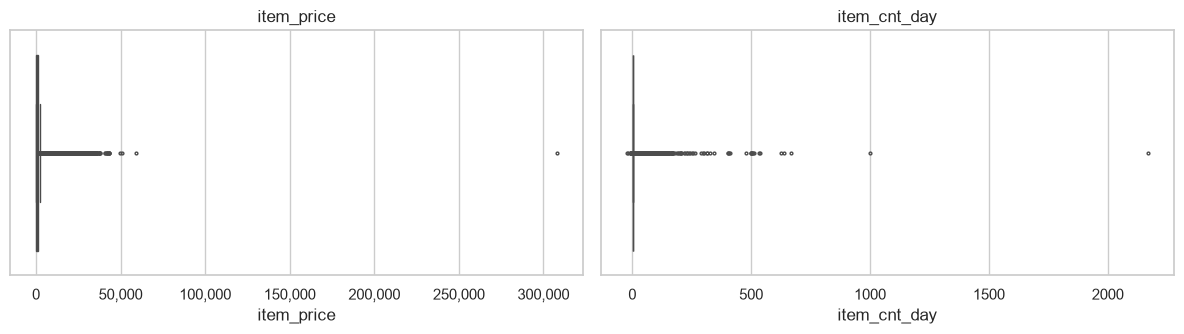

In [12]:
# Percentiles altos de precio y cantidad como referencia de lo "normal"
percentiles = sales[["item_price", "item_cnt_day"]].quantile([0.5, 0.99, 0.999])  # mediana, p99 y p99.9
percentiles.index = ["p50 (mediana)", "p99", "p99.9"]  # etiquetas legibles
display(percentiles)

# Las 5 transacciones más caras y las 5 de mayor cantidad, con el nombre del producto
nombres = items.set_index("item_id")["item_name"]  # diccionario item_id -> nombre
for col in ["item_price", "item_cnt_day"]:
    top = sales.nlargest(5, col).copy()  # 5 filas con el valor más alto
    top["item_name"] = top["item_id"].map(nombres)  # agrega el nombre del producto
    print(f"\nTop 5 por {col}:")
    display(top)

# Diagramas de caja: muestran la distancia entre los valores extremos y el resto de los datos
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=sales["item_price"], ax=axes[0], color="steelblue", fliersize=2)  # precios
axes[0].set_title("item_price")
axes[0].xaxis.set_major_formatter(MILES)
sns.boxplot(x=sales["item_cnt_day"], ax=axes[1], color="darkorange", fliersize=2)  # cantidades
axes[1].set_title("item_cnt_day")
plt.tight_layout()
plt.show()

**Interpretación.** El 99 % de las transacciones cuesta como máximo 5,999 rublos y mueve hasta 5 unidades; el 99.9 % no pasa de 23,990 rublos ni de 22 unidades. Hay dos casos muy alejados del resto:

- un precio de **307,980** (producto 6066, "Radmin 3 - 522 licencias", una venta de licencias por volumen que solo aparece una vez), casi 13 veces el percentil 99.9;
- una venta de **2,169 unidades** en un día del producto 11373, un servicio de envío ("Entrega a punto Boxberry") de la tienda online 12, a un precio de 0.91.

Las demás cantidades altas (1,000 bolsas, 600 boletos para la feria "ИгроМир 2015", el lanzamiento de GTA V para PC) son raras, pero corresponden a eventos de negocio reales.

## 13. Registros duplicados (4c)

Se buscan filas **exactamente iguales** en `sales_train` (misma fecha, tienda, producto, precio y cantidad). También se revisa si se repiten los IDs en los catálogos y en `test`.

In [13]:
# Filas idénticas en todas las columnas (keep=False marca todas las copias)
duplicados = sales[sales.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])
print(f"Filas duplicadas exactas (copias adicionales): {sales.duplicated().sum()}")
display(duplicados)

# Los IDs de los catálogos y de test deben ser únicos
print("IDs repetidos -> items:", items["item_id"].duplicated().sum(),
      "| categorías:", categories["item_category_id"].duplicated().sum(),
      "| tiendas:", shops["shop_id"].duplicated().sum(),
      "| pares en test:", test.duplicated(["shop_id", "item_id"]).sum())

Filas duplicadas exactas (copias adicionales): 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


IDs repetidos -> items: 0 | categorías: 0 | tiendas: 0 | pares en test: 0


**Interpretación.** Hay **6 filas duplicadas** exactas (12 filas en total con sus copias). Todas son de 1 unidad, y 4 de ellas son del mismo producto (3423) en distintas tiendas. Su peso es despreciable (0.0002 %) y no hay forma de distinguir un doble registro de dos ventas iguales en el mismo día. Los catálogos no tienen IDs repetidos y `test` no repite pares.

## 14. Tiendas repetidas en `shops.csv` (4c)

Se buscan tiendas con el mismo nombre o casi igual pero distinto ID. Para cada tienda se calcula su primer y último mes con ventas, el número de meses activos y si aparece en `test.csv`. Si dos IDs con el mismo nombre **nunca venden en el mismo mes** y uno empieza justo cuando el otro termina, se trata de la misma tienda registrada con dos IDs.

In [14]:
# Unidades vendidas por tienda y mes (filas: tiendas, columnas: meses)
ventas_tienda_mes = sales.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
activa = ventas_tienda_mes != 0  # True en los meses en que la tienda registró movimiento

# Resumen de actividad de cada tienda
actividad = pd.DataFrame({
    "shop_name": shops.set_index("shop_id")["shop_name"],  # nombre de la tienda
    "primer_mes": activa.idxmax(axis=1),  # primer mes con ventas
    "ultimo_mes": activa.apply(lambda fila: fila[fila].index.max(), axis=1),  # último mes con ventas
    "meses_activos": activa.sum(axis=1),  # número de meses con ventas
    "en_test": shops["shop_id"].isin(test["shop_id"]).values,  # ¿hay que predecir esta tienda?
})

# Pares candidatos a duplicado: nombre casi igual (revisados manualmente en la lista de tiendas)
CANDIDATOS = [(0, 57), (1, 58), (10, 11), (39, 40)]
for a, b in CANDIDATOS:
    meses_comunes = (activa.loc[a] & activa.loc[b]).sum()  # meses en que ambas venden a la vez
    print(f"\nTiendas {a} y {b} -> meses con ventas simultáneas: {meses_comunes}")
    display(actividad.loc[[a, b]])


Tiendas 0 y 57 -> meses con ventas simultáneas: 0


,shop_name,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,,
0,"!Якутск Орджоникидзе, 56 фран",0,1,2,False
57,"Якутск Орджоникидзе, 56",2,33,32,True



Tiendas 1 y 58 -> meses con ventas simultáneas: 0


,shop_name,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,,
1,"!Якутск ТЦ ""Центральный"" фран",0,1,2,False
58,"Якутск ТЦ ""Центральный""",2,33,32,True



Tiendas 10 y 11 -> meses con ventas simultáneas: 0


,shop_name,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,,
10,Жуковский ул. Чкалова 39м?,0,33,33,True
11,Жуковский ул. Чкалова 39м²,25,25,1,False



Tiendas 39 y 40 -> meses con ventas simultáneas: 11


,shop_name,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,,
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",14,33,20,True
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14,24,11,False


**Interpretación.**

- **0/57 y 1/58 (Yakutsk):** los nombres son iguales salvo el prefijo "!" y el sufijo "фран" (franquicia). Las tiendas 0 y 1 venden solo en los meses 0 y 1, y la 57 y la 58 empiezan justo en el mes 2. Nunca coinciden: es la misma tienda que cambió de ID.
- **10/11 (Zhukovsky):** el nombre solo difiere en un carácter mal codificado ("м?" frente a "м²"). La 11 vende únicamente en el mes 25, un mes en el que la 10 no registra ventas. Es la misma tienda.
- **39/40 (Rostov):** la 40 agrega "Островной" ("isla") al nombre y **ambas venden a la vez durante 11 meses**. Son puntos de venta distintos dentro del mismo centro comercial; no se unifican.

Las tiendas 0, 1 y 11 no están en `test`, por lo que unificarlas no cambia lo que hay que predecir, pero alarga el historial de las tiendas 57, 58 y 10.

## 15. Estrategia de limpieza y aplicación (4b y 4c)

Con la evidencia de las secciones 10 a 14 se definió la siguiente estrategia (guardada en `pipeline_config.yaml` para reutilizarla en las fases siguientes):

| Caso | Evidencia | Decisión | Justificación |
|---|---|---|---|
| Valores nulos | No hay nulos en ninguna tabla | Ninguna acción | No hace falta eliminar ni imputar. |
| Tiendas repetidas 0/57, 1/58, 11/10 | Mismo nombre (o casi), sin meses en común | **Unificar** al ID vigente (57, 58, 10) | Es la misma tienda con dos IDs; unirlas da historiales completos. |
| Tiendas 39/40 | Nombres parecidos pero venden a la vez 11 meses | Se mantienen separadas | Operan en paralelo: son locales distintos. |
| Precio ≤ 0 | 1 fila con precio −1 | **Imputar** con la mediana del producto en esa tienda | La venta es real; solo el precio está mal registrado. |
| Cantidades negativas | ~0.25 % de las filas | **Conservar** | Son devoluciones y restan en `item_cnt_month`, que es como se define el target. |
| Outliers extremos | 1 precio > 100,000 y 1 cantidad > 1,000 | **Eliminar** las filas | Son casos aislados (licencia por volumen y un servicio de entrega) que distorsionan las métricas. |
| Duplicados exactos | 6 copias de 1 unidad | **Conservar** | No hay evidencia de que sean errores; pueden ser dos ventas iguales en el mismo día. |

La siguiente celda aplica estas decisiones leyendo los parámetros del YAML y muestra cuántas filas cambian en cada paso. El resto del notebook trabaja con los datos limpios.

In [15]:
# Parámetros de limpieza definidos en pipeline_config.yaml
LIMPIEZA = CONFIG["cleaning"]
filas_iniciales = len(sales)  # tamaño antes de limpiar

# 1) Unificar tiendas duplicadas: el ID antiguo se reemplaza por el vigente (en ventas y en test)
mapa_tiendas = {int(k): int(v) for k, v in LIMPIEZA["shop_id_map"].items()}
filas_tienda = sales["shop_id"].isin(mapa_tiendas).sum()  # filas afectadas
sales["shop_id"] = sales["shop_id"].replace(mapa_tiendas).astype("int8")
test["shop_id"] = test["shop_id"].replace(mapa_tiendas)
print(f"1) Tiendas unificadas {mapa_tiendas}: {filas_tienda:,} filas reasignadas")

# 2) Eliminar outliers extremos de precio y de cantidad diaria
es_outlier = (sales["item_price"] > LIMPIEZA["max_item_price"]) | (sales["item_cnt_day"] > LIMPIEZA["max_item_cnt_day"])
sales = sales[~es_outlier].copy()
print(f"2) Outliers extremos eliminados: {es_outlier.sum()} filas")

# 3) Imputar precios <= 0 con la mediana del mismo producto en la misma tienda
precio_malo = sales["item_price"] <= 0
mediana_tienda_producto = sales[~precio_malo].groupby(["shop_id", "item_id"])["item_price"].median()  # precios válidos
claves = list(zip(sales.loc[precio_malo, "shop_id"], sales.loc[precio_malo, "item_id"]))  # (tienda, producto) a corregir
sales.loc[precio_malo, "item_price"] = [mediana_tienda_producto[k] for k in claves]
print(f"3) Precios <= 0 imputados con la mediana tienda-producto: {precio_malo.sum()} filas")

# 4) Devoluciones y duplicados: se conservan según la configuración
print(f"4) Devoluciones conservadas: {LIMPIEZA['keep_returns']} | duplicados eliminados: {LIMPIEZA['drop_exact_duplicates']}")
if LIMPIEZA["drop_exact_duplicates"]:
    sales = sales.drop_duplicates()

print(f"\nFilas: {filas_iniciales:,} -> {len(sales):,} (eliminadas: {filas_iniciales - len(sales)})")
print("Precios <= 0 restantes:", (sales["item_price"] <= 0).sum(), "| tiendas distintas:", sales["shop_id"].nunique())

1) Tiendas unificadas {0: 57, 1: 58, 11: 10}: 16,034 filas reasignadas
2) Outliers extremos eliminados: 2 filas


3) Precios <= 0 imputados con la mediana tienda-producto: 1 filas
4) Devoluciones conservadas: True | duplicados eliminados: False

Filas: 2,935,849 -> 2,935,847 (eliminadas: 2)
Precios <= 0 restantes: 0 | tiendas distintas: 57


## 16. Variables derivadas: ingresos, categoría y calendario

Se agregan al conjunto de ventas las columnas que se usarán en el resto del análisis:

- **`revenue`** = `item_price × item_cnt_day`: ingreso de la transacción en rublos (negativo en las devoluciones).
- **`item_category_id`**: categoría del producto, tomada del catálogo `items`.
- **Calendario**: año, mes del año, día de la semana y semana, extraídos de la fecha.

In [16]:
# Ingreso de cada transacción (se usa float64 para que las sumas grandes no pierdan precisión)
sales["revenue"] = sales["item_price"].astype("float64") * sales["item_cnt_day"].astype("float64")

# Categoría de cada producto: se cruza con el catálogo de productos
sales = sales.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")

# Variables de calendario
sales["year"] = sales["date"].dt.year.astype("int16")  # año (2013, 2014, 2015)
sales["month"] = sales["date"].dt.month.astype("int8")  # mes del año (1-12)
sales["weekday"] = sales["date"].dt.day_of_week.astype("int8")  # día de la semana (0 = lunes, 6 = domingo)
sales["week"] = sales["date"].dt.to_period("W").dt.start_time  # lunes de la semana a la que pertenece la fecha

print("Productos sin categoría después del cruce:", sales["item_category_id"].isna().sum())
sales.head()

Productos sin categoría después del cruce: 0


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,revenue,item_category_id,year,month,weekday,week
0,2013-01-02,0,59,22154,999.00,1.00,999.00,37,2013,1,2,2012-12-31
1,2013-01-03,0,25,2552,899.00,1.00,899.00,58,2013,1,3,2012-12-31
2,2013-01-05,0,25,2552,899.00,-1.00,-899.00,58,2013,1,5,2012-12-31
3,2013-01-06,0,25,2554,"1,709.05",1.00,"1,709.05",58,2013,1,6,2012-12-31
4,2013-01-15,0,25,2555,"1,099.00",1.00,"1,099.00",56,2013,1,1,2013-01-14


## 17. Métricas estadísticas básicas (5a)

Media, mediana, mínimo, máximo y desviación estándar del precio unitario, de las unidades por transacción y de los ingresos por transacción.

In [17]:
# Estadísticas descriptivas de las tres variables numéricas principales
estadisticas = sales[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"]).T
estadisticas.columns = ["media", "mediana", "mínimo", "máximo", "desv_estándar"]  # nombres en español
estadisticas

,media,mediana,mínimo,máximo,desv_estándar
item_price,890.75,399.00,0.07,"59,200.00","1,720.49"
item_cnt_day,1.24,1.00,-22.00,"1,000.00",2.29
revenue,"1,157.63",449.00,"-68,970.00","1,829,990.00","5,680.78"


**Interpretación.**

- **Precio:** la media (891) duplica a la mediana (399) y la desviación estándar es casi el doble de la media. La distribución tiene una cola larga hacia la derecha: muchos productos baratos (películas, música) y pocos muy caros (consolas, software).
- **Cantidad por transacción:** la mediana es 1 y la media 1.24. Casi todas las filas son ventas de una unidad; los valores grandes son excepcionales.
- **Ingresos por transacción:** la media es 1,158 y la mediana 449, con un rango de −68,970 (una devolución cara) a 1.83 millones. Igual que el precio, tiene una asimetría positiva fuerte.

Las tres variables son muy asimétricas, así que conviene describirlas con la **mediana** o con transformaciones logarítmicas, no solo con la media.

## 18. Distribución de ventas por producto y categoría (5b-i)

Se suman las unidades vendidas por producto y por categoría para ver cómo se reparten las ventas. Como unos pocos productos venden muchísimo y la mayoría muy poco, los histogramas usan escala logarítmica. También se calcula qué parte de las ventas concentra el 1 % y el 10 % de los productos más vendidos.

Unidades por producto (resumen):


,count,mean,std,min,25%,50%,75%,max
unidades,"21,806.00",167.20,"1,365.86",-11.00,7.00,33.00,124.00,"187,642.00"


El top 1% de productos (218) concentra el 28.1% de las unidades
El top 10% de productos (2,180) concentra el 67.6% de las unidades

Categorías con ventas: 84 de 84


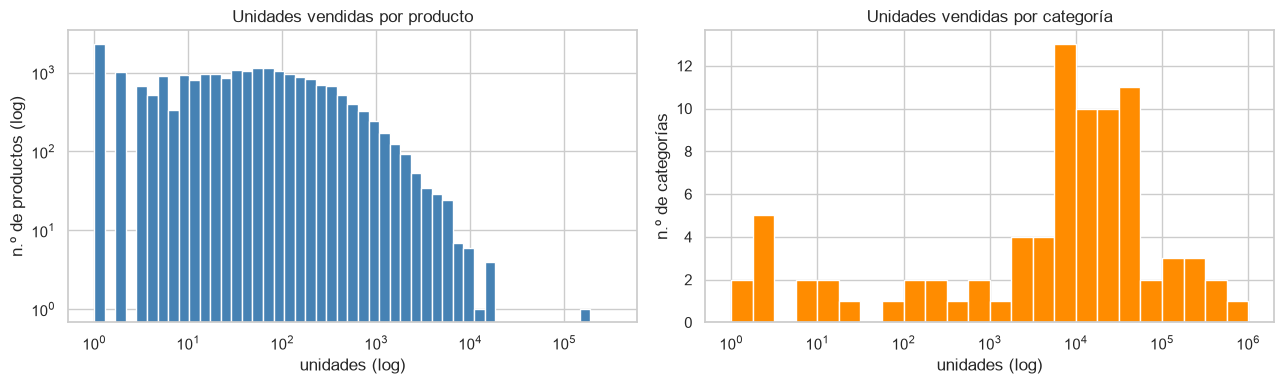

In [18]:
# Unidades e ingresos totales por producto
por_producto = sales.groupby("item_id").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
print("Unidades por producto (resumen):")
display(por_producto["unidades"].describe().to_frame().T)

# Concentración: participación del 1 % y del 10 % de productos con más unidades
orden = por_producto["unidades"].sort_values(ascending=False)
for p in [0.01, 0.10]:
    n = int(len(orden) * p)  # cantidad de productos en ese top
    print(f"El top {p:.0%} de productos ({n:,}) concentra el {orden.iloc[:n].sum() / orden.sum():.1%} de las unidades")

# Unidades totales por categoría, con el número de productos de cada una
por_categoria = sales.groupby("item_category_id").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique")
)
print(f"\nCategorías con ventas: {len(por_categoria)} de {len(categories)}")

# Histogramas en escala logarítmica de unidades por producto y por categoría
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(por_producto["unidades"].clip(lower=1), bins=np.logspace(0, 5.5, 50), color="steelblue")  # productos
axes[0].set(xscale="log", yscale="log", title="Unidades vendidas por producto", xlabel="unidades (log)", ylabel="n.º de productos (log)")
axes[1].hist(por_categoria["unidades"].clip(lower=1), bins=np.logspace(0, 6, 25), color="darkorange")  # categorías
axes[1].set(xscale="log", title="Unidades vendidas por categoría", xlabel="unidades (log)", ylabel="n.º de categorías")
plt.tight_layout()
plt.show()

**Interpretación.** Las ventas están **muy concentradas**:

- el **1 %** de los productos (218) concentra el **28 %** de las unidades;
- el **10 %** de los productos concentra el **68 %**;
- la mediana es de 33 unidades por producto en casi tres años, y un 25 % de los productos vende 7 o menos.

El histograma en escala log-log muestra una distribución de cola larga típica del comercio minorista. Las 84 categorías tienen ventas, pero también con tamaños muy distintos (de 1 a más de 600 mil unidades). Para el modelo, esto significa que la mayoría de los pares tienda-producto tendrá ventas mensuales de 0 o 1, y unos pocos tendrán valores altos.

## 19. Distribución de ventas por tienda (5b-ii)

Se suman unidades e ingresos por tienda (ya con los IDs unificados) y se calcula la participación de cada una en el total.

Unidades por tienda (resumen):


,count,mean,std,min,25%,50%,75%,max
unidades,57.00,"63,965.54","58,413.40",330.00,"25,838.00","53,886.00","71,201.00","310,777.00"


Las 5 tiendas más grandes ([31, 25, 54, 28, 57]) concentran el 29.5 % de las unidades


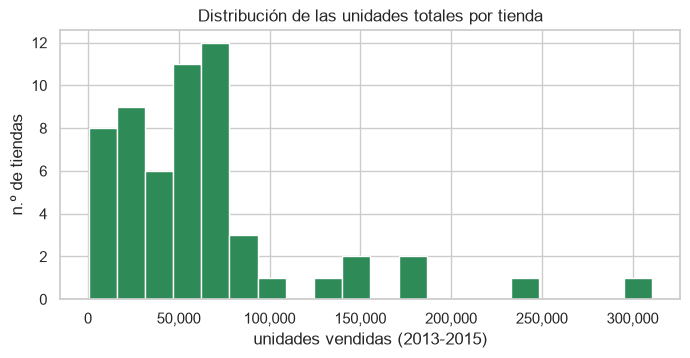

In [19]:
# Unidades, ingresos y meses activos por tienda
por_tienda = sales.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), meses_activos=("date_block_num", "nunique")
)
por_tienda["participacion_unidades_%"] = por_tienda["unidades"] / por_tienda["unidades"].sum() * 100  # % del total
print("Unidades por tienda (resumen):")
display(por_tienda["unidades"].describe().to_frame().T)

# Concentración: las 5 tiendas más grandes
top5 = por_tienda["participacion_unidades_%"].nlargest(5)
print(f"Las 5 tiendas más grandes ({list(top5.index)}) concentran el {top5.sum():.1f} % de las unidades")

# Histograma: cuántas tiendas hay en cada rango de ventas totales
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(por_tienda["unidades"], bins=20, color="seagreen")
ax.set(title="Distribución de las unidades totales por tienda", xlabel="unidades vendidas (2013-2015)", ylabel="n.º de tiendas")
ax.xaxis.set_major_formatter(MILES)
plt.show()

**Interpretación.** Después de unificar quedan **57 tiendas**. La tienda típica (mediana) vendió unas 54 mil unidades en el periodo, aunque el rango va de 330 a 311 mil. Las 5 más grandes (31, 25, 54, 28 y 57) concentran el **30 %** de las unidades. La distribución tiene una cola a la derecha, pero es menos extrema que la de productos; la mayoría de las tiendas está entre 25 mil y 71 mil unidades. Las tiendas con muy pocas unidades son tiendas que estuvieron abiertas poco tiempo o que no son físicas (se analizan en la sección 26).

## 20. Distribución de ventas por periodo: día, semana, mes y año (5b-iii)

Se agregan las unidades totales de la cadena a distintas frecuencias y se comparan sus distribuciones. Como 2015 solo tiene datos hasta octubre, la comparación anual usa el **promedio mensual** además del total.

,count,mean,std,min,25%,50%,75%,max
diario,"1,034.00","3,526.15","1,586.04","1,274.00","2,464.25","3,144.50","4,257.00","13,343.00"
semanal,146.00,"24,645.99","7,801.26","12,389.00","19,959.25","24,500.50","27,672.50","57,680.00"
mensual,34.00,"107,236.35","28,541.96","63,187.00","85,968.50","107,306.00","125,358.50","183,341.00"


,unidades,meses,promedio_mensual
year,,,
2013,"1,562,732.00",12,"130,227.67"
2014,"1,320,889.00",12,"110,074.08"
2015,"762,415.00",10,"76,241.50"


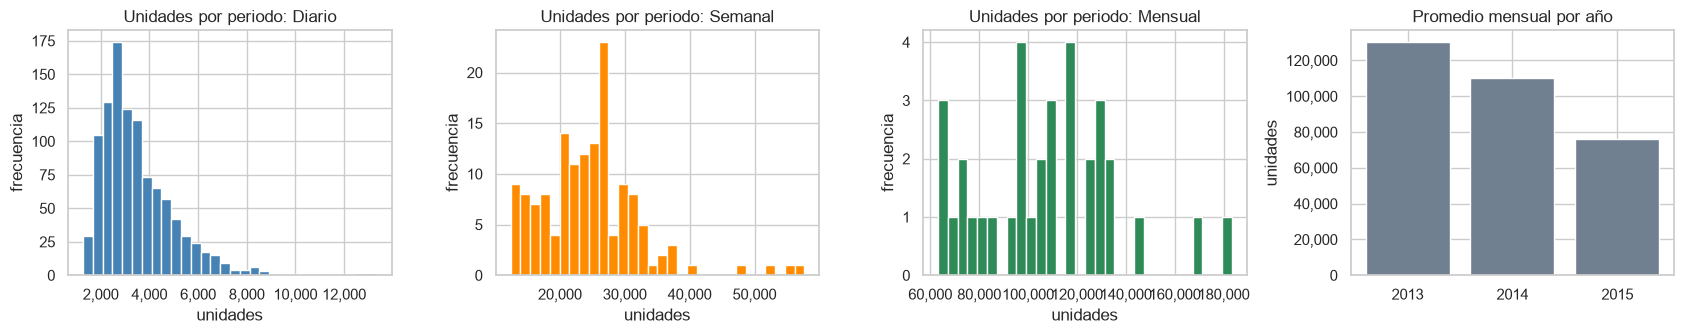

In [20]:
# Unidades totales de la cadena a distintas frecuencias
por_dia = sales.groupby("date")["item_cnt_day"].sum()  # total diario
por_semana = sales.groupby("week")["item_cnt_day"].sum()  # total semanal
por_semana = por_semana.iloc[1:-1]  # se excluyen la primera y la última semana porque están incompletas
por_mes = sales.groupby("date_block_num")["item_cnt_day"].sum()  # total mensual
por_anio = sales.groupby("year").agg(unidades=("item_cnt_day", "sum"), meses=("date_block_num", "nunique"))
por_anio["promedio_mensual"] = por_anio["unidades"] / por_anio["meses"]  # comparable entre años

# Resumen estadístico de cada frecuencia
resumen_periodos = pd.DataFrame({
    "diario": por_dia.describe(), "semanal": por_semana.describe(), "mensual": por_mes.describe()
}).T
display(resumen_periodos)
display(por_anio)

# Histogramas de las tres frecuencias y barras del promedio mensual por año
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, serie, titulo, color in zip(axes[:3], [por_dia, por_semana, por_mes], ["Diario", "Semanal", "Mensual"], ["steelblue", "darkorange", "seagreen"]):
    ax.hist(serie, bins=30, color=color)  # distribución de los totales de cada periodo
    ax.set(title=f"Unidades por periodo: {titulo}", xlabel="unidades", ylabel="frecuencia")
    ax.xaxis.set_major_formatter(MILES)
axes[3].bar(por_anio.index.astype(str), por_anio["promedio_mensual"], color="slategray")  # promedio mensual por año
axes[3].set(title="Promedio mensual por año", ylabel="unidades")
axes[3].yaxis.set_major_formatter(MILES)
plt.tight_layout()
plt.show()

**Interpretación.**

- **Diario:** la mediana es de unas 3,145 unidades por día, con días de hasta 13,343 (los picos de fin de año).
- **Semanal:** unas 24,500 unidades de mediana por semana.
- **Mensual:** entre 63 mil y 183 mil unidades por mes, con una mediana de 107 mil.
- **Anual:** el promedio mensual cae de **130 mil (2013)** a **110 mil (2014)** y a **76 mil (2015)**, una baja de más del 40 % en dos años.

En todas las frecuencias la distribución tiene una cola a la derecha, causada por los meses de diciembre. La caída anual es la señal más importante para el pronóstico: noviembre de 2015 debería estar por debajo de noviembre de 2014.

## 21. Evolución de las ventas en el tiempo (6a)

Se grafican las unidades vendidas por día (con una media móvil de 30 días para ver la tendencia sin el ruido diario) y las unidades e ingresos totales por mes.

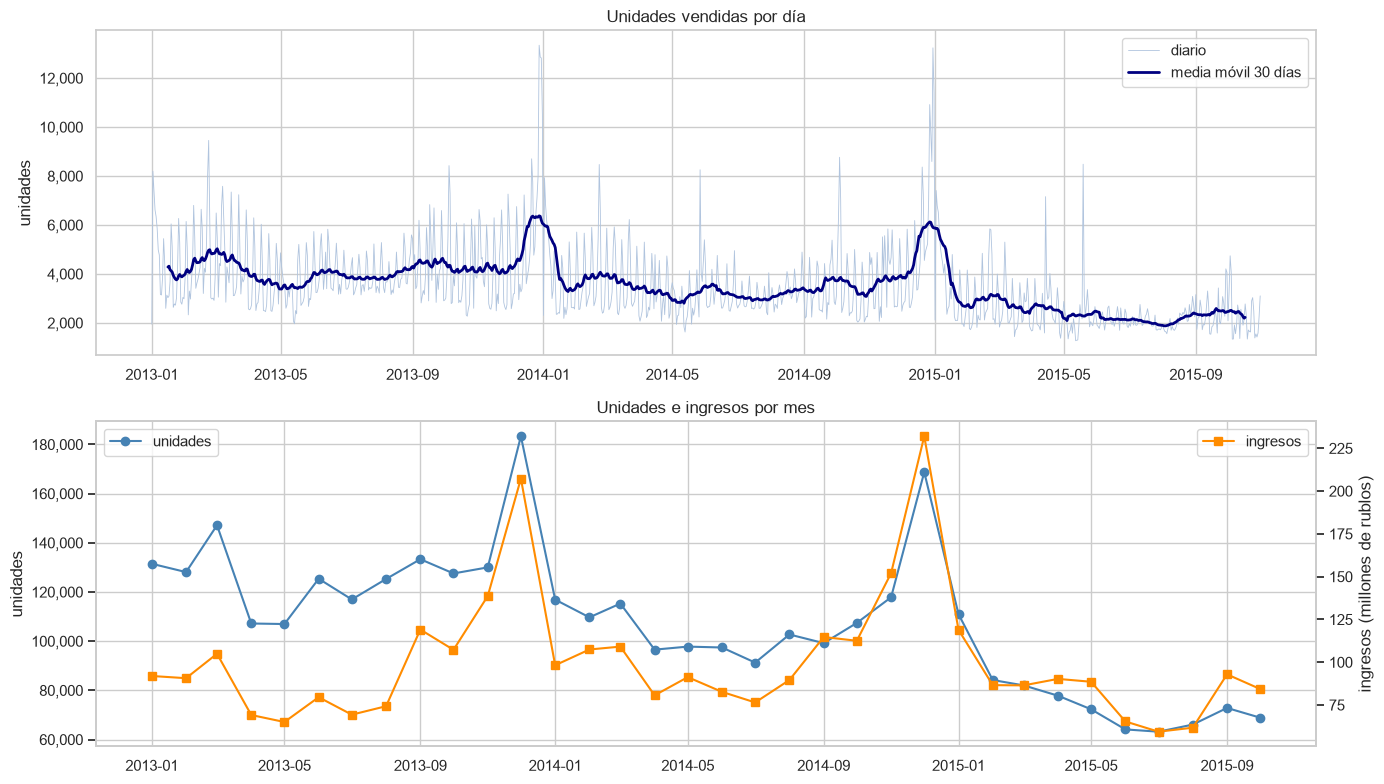

In [21]:
# Unidades e ingresos mensuales de la cadena (índice: date_block_num)
mensual = sales.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
mensual.index = pd.period_range("2013-01", periods=len(mensual), freq="M").to_timestamp()  # fechas reales en el eje

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Panel superior: serie diaria y su media móvil de 30 días
axes[0].plot(por_dia.index, por_dia.values, lw=0.6, color="lightsteelblue", label="diario")
axes[0].plot(por_dia.index, por_dia.rolling(30, center=True).mean(), lw=2, color="navy", label="media móvil 30 días")
axes[0].set(title="Unidades vendidas por día", ylabel="unidades")
axes[0].yaxis.set_major_formatter(MILES)
axes[0].legend()

# Panel inferior: unidades (eje izquierdo) e ingresos (eje derecho) por mes
axes[1].plot(mensual.index, mensual["unidades"], marker="o", color="steelblue", label="unidades")
axes[1].set(title="Unidades e ingresos por mes", ylabel="unidades")
axes[1].yaxis.set_major_formatter(MILES)
eje_ingresos = axes[1].twinx()  # segundo eje vertical para los ingresos
eje_ingresos.plot(mensual.index, mensual["ingresos"] / 1e6, marker="s", color="darkorange", label="ingresos")
eje_ingresos.set_ylabel("ingresos (millones de rublos)")
eje_ingresos.grid(False)
axes[1].legend(loc="upper left")
eje_ingresos.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretación.**

- **La serie diaria** oscila mucho de un día a otro, por el ciclo semanal. La media móvil muestra un nivel que baja de forma sostenida, de unas 4,000-4,500 unidades diarias en 2013 a unas 2,000-2,500 en 2015, interrumpido por los picos de fin de año.
- **Unidades e ingresos mensuales** tienen la misma forma general: un pico muy marcado en **diciembre** de cada año y una tendencia a la baja.
- Sin embargo, los ingresos caen **menos** que las unidades. Desde la segunda mitad de 2014 los ingresos se mantienen relativamente altos, y en diciembre de 2014 superan a diciembre de 2013 con menos unidades. Esto indica que el **precio medio por unidad aumentó** (hipótesis: por la mezcla de productos más caros, como las consolas y juegos de PS4, o por la devaluación del rublo a fines de 2014; los datos no permiten separar ambas causas).

## 22. Tendencia y estacionalidad (6b-i y 6b-ii)

La **descomposición clásica aditiva** separa la serie mensual de unidades en tres partes: **tendencia** (dirección de largo plazo), **estacionalidad** (patrón que se repite cada 12 meses) y **residuo** (lo que no explican las dos anteriores). Con 34 meses hay casi tres ciclos anuales, suficientes para estimar un patrón estacional de periodo 12.

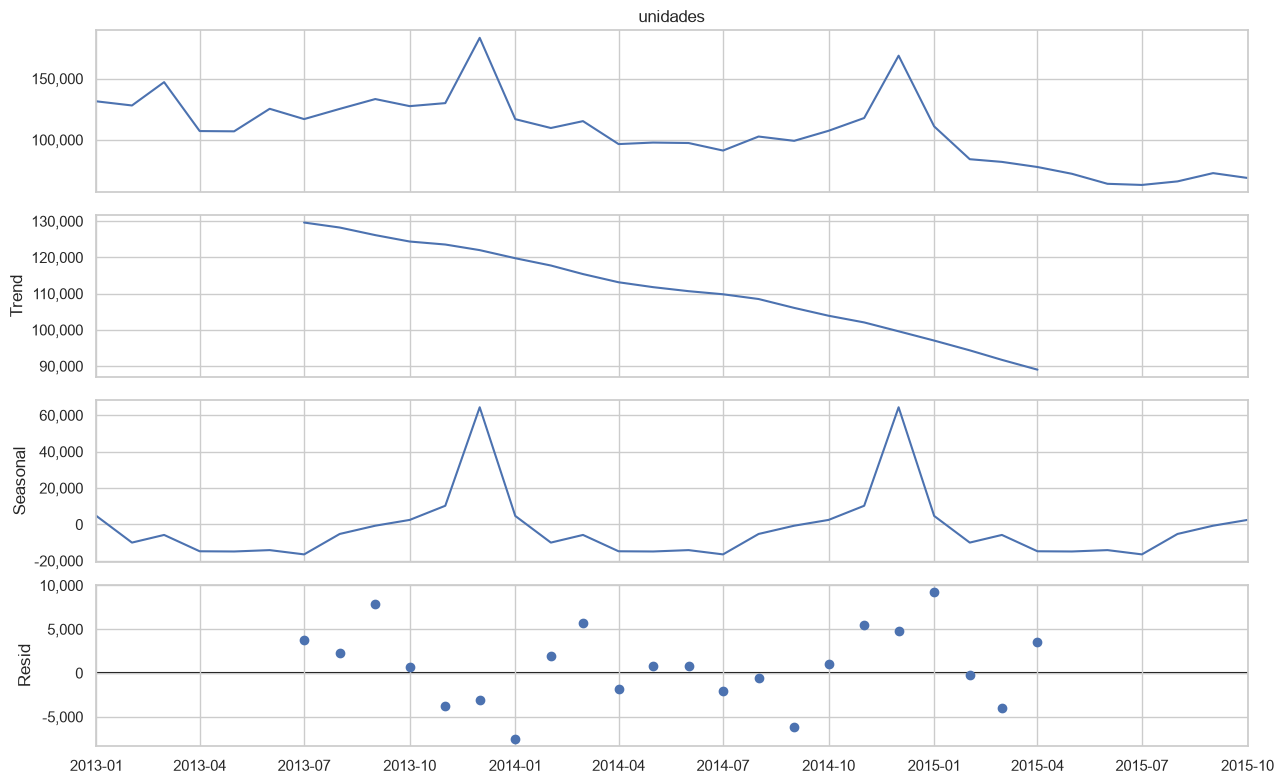

mes,1,2,3,4,5,6,7,8,9,10,11,12
efecto_estacional,"4,670.32","-9,968.20","-5,761.43","-14,743.29","-14,858.66","-14,105.08","-16,452.87","-5,228.20",-692.95,"2,487.11","10,266.73","64,386.53"


In [22]:
# Descomposición aditiva de la serie mensual con periodo anual (12 meses)
descomp = seasonal_decompose(mensual["unidades"], model="additive", period=12)
fig = descomp.plot()  # 4 paneles: serie, tendencia, estacionalidad y residuo
fig.set_size_inches(13, 8)
for ax in fig.axes:
    ax.yaxis.set_major_formatter(MILES)
plt.tight_layout()
plt.show()

# Componente estacional por mes del año: cuánto se aleja cada mes del nivel de la tendencia
estacional = descomp.seasonal.groupby(descomp.seasonal.index.month).first().rename("efecto_estacional")
estacional.index.name = "mes"
estacional.to_frame().T

**Interpretación.**

- **Tendencia:** es **decreciente y casi lineal**: pasa de unas 130 mil unidades mensuales a mediados de 2013 a unas 89 mil en abril de 2015 (la media móvil de 12 meses no está definida en los extremos de la serie).
- **Estacionalidad anual:** está bien definida. **Diciembre** suma unas **+64 mil unidades** sobre la tendencia; noviembre (+10 mil), enero (+5 mil) y octubre (+2.5 mil) también quedan por encima, mientras que de **febrero a julio** los meses quedan entre 6 mil y 16 mil por debajo.
- **Residuos:** son pequeños (±10 mil) comparados con la estacionalidad, así que tendencia y estacionalidad explican la mayor parte del comportamiento de la serie.

**Para el pronóstico de noviembre:** se espera un efecto estacional positivo moderado, pero sobre una tendencia que sigue bajando.

## 23. Picos y caídas abruptas (6b-iii)

Se calcula la variación porcentual de las unidades de un mes respecto del anterior para identificar los saltos más fuertes. También se listan los días con las ventas más altas y más bajas.

In [23]:
# Variación porcentual mes contra mes
variacion = mensual["unidades"].pct_change() * 100
tabla_var = pd.DataFrame({"unidades": mensual["unidades"], "variacion_%": variacion})
tabla_var.index = tabla_var.index.strftime("%Y-%m")  # etiqueta año-mes legible
print("Mayores subidas mensuales:")
display(tabla_var.nlargest(4, "variacion_%"))
print("Mayores caídas mensuales:")
display(tabla_var.nsmallest(4, "variacion_%"))

# Días extremos de toda la serie
dias = por_dia.to_frame("unidades")
dias["dia_semana"] = dias.index.day_name()  # nombre del día de la semana
print("Días con más unidades vendidas:")
display(dias.nlargest(5, "unidades"))
print("Días con menos unidades vendidas:")
display(dias.nsmallest(5, "unidades"))

Mayores subidas mensuales:


,unidades,variacion_%
2014-12,"168,755.00",43.20
2013-12,"183,341.00",41.02
2013-06,"125,381.00",17.21
2013-03,"147,142.00",14.87


Mayores caídas mensuales:


,unidades,variacion_%
2014-01,"116,899.00",-36.24
2015-01,"110,971.00",-34.24
2013-04,"107,190.00",-27.15
2015-02,"84,198.00",-24.13


Días con más unidades vendidas:


,unidades,dia_semana
date,,
2013-12-28,"13,343.00",Saturday
2014-12-30,"13,236.00",Tuesday
2013-12-29,"12,863.00",Sunday
2013-12-30,"12,823.00",Monday
2014-12-31,"11,394.00",Wednesday


Días con menos unidades vendidas:


,unidades,dia_semana
date,,
2015-05-12,"1,274.00",Tuesday
2015-05-13,"1,294.00",Wednesday
2015-05-14,"1,302.00",Thursday
2015-10-05,"1,340.00",Monday
2015-10-19,"1,341.00",Monday


**Interpretación.**

- **Picos:** las mayores subidas son las de **diciembre** (+41 % en 2013 y +43 % en 2014 respecto de noviembre), y los cinco días con más ventas están entre el 28 y el 31 de diciembre, por las compras de Año Nuevo, la fiesta principal de regalos en Rusia.
- **Caídas:** las mayores caídas son las de **enero** (−36 % y −34 %), que son el regreso a la normalidad después del pico. También caen abril de 2013 (−27 %, tras un marzo alto) y febrero de 2015 (−24 %).
- **Días más bajos:** del 12 al 14 de mayo de 2015 y algunos lunes de octubre de 2015, en línea con el nivel bajo del último año.

Fuera de estos efectos de calendario no se observan caídas atribuibles a problemas de datos: ningún mes queda con ventas anormalmente bajas.

## 24. Ciclos por día de la semana y por mes del año (6b-iv)

- **Día de la semana**: promedio de unidades vendidas por día, separando lunes a domingo.
- **Mes del año**: unidades de cada mes, con una línea por año para comparar si el patrón se repite.

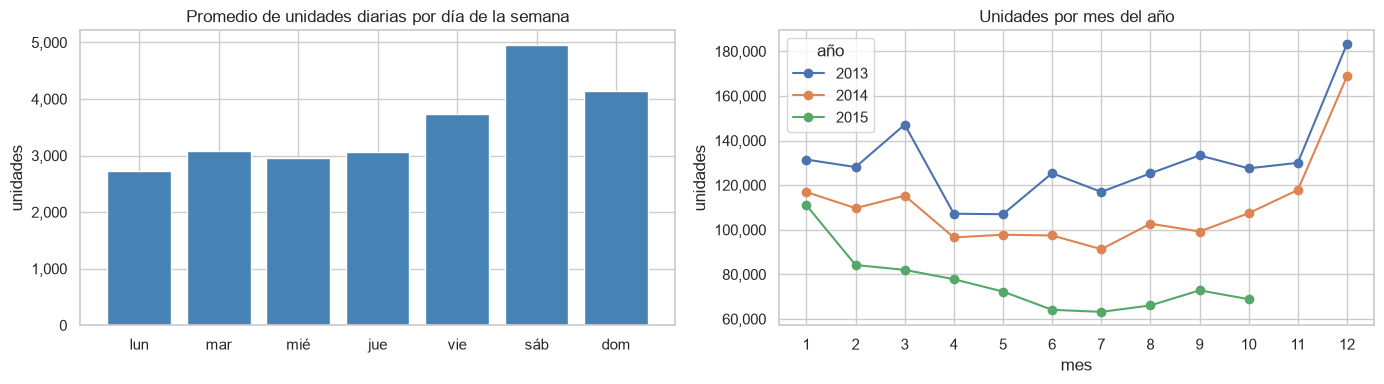

Índice por día de la semana (1 = promedio):
lun   0.77
mar   0.87
mié   0.84
jue   0.87
vie   1.06
sáb   1.41
dom   1.18


In [24]:
# Promedio de unidades diarias según el día de la semana
diario = por_dia.to_frame("unidades")
diario["weekday"] = diario.index.day_of_week  # 0 = lunes ... 6 = domingo
promedio_dia = diario.groupby("weekday")["unidades"].mean()
NOMBRES_DIA = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

# Unidades por mes del año, en columnas por año
mes_anio = sales.groupby(["year", "month"])["item_cnt_day"].sum().unstack(level=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(NOMBRES_DIA, promedio_dia.values, color="steelblue")  # barras por día de la semana
axes[0].set(title="Promedio de unidades diarias por día de la semana", ylabel="unidades")
axes[0].yaxis.set_major_formatter(MILES)
for anio in mes_anio.columns:
    axes[1].plot(mes_anio.index, mes_anio[anio], marker="o", label=str(anio))  # una línea por año
axes[1].set(title="Unidades por mes del año", xlabel="mes", ylabel="unidades", xticks=range(1, 13))
axes[1].yaxis.set_major_formatter(MILES)
axes[1].legend(title="año")
plt.tight_layout()
plt.show()

# Índice día de la semana: promedio de cada día dividido entre el promedio general
print("Índice por día de la semana (1 = promedio):")
print((promedio_dia / promedio_dia.mean()).round(2).set_axis(NOMBRES_DIA).to_string())

**Interpretación.**

- **Ciclo semanal:** es muy marcado. El **sábado** vende un **41 % más** que el promedio, el domingo un 18 % más y el viernes un 6 % más, mientras que el **lunes** es el día más bajo (−23 %). Es un patrón típico de tiendas en centros comerciales.
- **Ciclo anual:** se repite en los tres años, con un pico en diciembre y meses bajos de abril a julio. Cada año la curva completa está **por debajo** de la del año anterior, lo que confirma la tendencia decreciente.

El ciclo semanal desaparece al agregar por mes, porque todos los meses tienen 4 fines de semana completos y a veces 5, pero explica la fuerte autocorrelación de la serie diaria (sección 33).

## 25. Productos y categorías más y menos vendidos (7a)

Se listan los 10 productos y las 10 categorías con más unidades vendidas, y los que menos venden. Para los menos vendidos se resume cuántos productos venden muy poco, porque hay miles con una sola unidad y una lista de 10 no sería representativa.

In [25]:
# Nombres de productos y categorías para las tablas
nombre_categoria = categories.set_index("item_category_id")["item_category_name"]
tabla_prod = por_producto.join(items.set_index("item_id")[["item_name", "item_category_id"]])  # agrega nombre y categoría
tabla_cat = por_categoria.join(nombre_categoria)  # agrega el nombre de la categoría

print("Top 10 productos por unidades:")
display(tabla_prod.nlargest(10, "unidades"))
print("Top 10 categorías por unidades:")
display(tabla_cat.nlargest(10, "unidades"))

# Productos menos vendidos: resumen por tramos de unidades totales
print("Productos según sus unidades totales en 34 meses:")
tramos = pd.cut(por_producto["unidades"], bins=[-np.inf, 0, 1, 5, 20, np.inf], labels=["<= 0", "1", "2-5", "6-20", "> 20"])
display(tramos.value_counts().sort_index().to_frame("productos").assign(porcentaje=lambda d: d["productos"] / d["productos"].sum() * 100))
print("Ejemplos de productos con ventas netas <= 0 (las devoluciones igualan o superan a las ventas):")
display(tabla_prod.nsmallest(5, "unidades"))

print("Las 10 categorías con menos unidades:")
display(tabla_cat.nsmallest(10, "unidades"))

Top 10 productos por unidades:


,unidades,ingresos,item_name,item_category_id
item_id,,,,
20949,"187,642.00","928,863.70",Фирменный пакет майка 1С Интерес белый (34*42)...,71
2808,"17,245.00","16,852,778.42","Diablo III [PC, Jewel, русская версия]",30
3732,"16,642.00","43,617,975.49","Grand Theft Auto V [PS3, русские субтитры]",19
17717,"15,830.00","17,200,825.93",Прием денежных средств для 1С-Онлайн,79
5822,"14,515.00","15,408,983.12",Playstation Store пополнение бумажника: Карта ...,35
3734,"11,688.00","31,065,160.29","Grand Theft Auto V [Xbox 360, русские субтитры]",23
6675,"10,289.00","219,391,488.78",Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,12
3731,"10,099.00","19,983,482.88","Grand Theft Auto V [PC, русские субтитры]",30
1855,"10,032.00","9,357,024.78","Battlefield 4 [PC, русская версия]",30


Top 10 categorías por unidades:


,unidades,ingresos,productos,item_category_name
item_category_id,,,,
40,"634,171.00","169,944,221.68",4964,Кино - DVD
30,"456,540.00","257,519,291.07",751,Игры PC - Стандартные издания
55,"348,591.00","100,022,563.57",2327,Музыка - CD локального производства
19,"254,887.00","412,052,780.89",625,Игры - PS3
37,"203,284.00","90,478,731.85",1777,Кино - Blu-Ray
71,"187,998.00","934,206.61",6,"Подарки - Сумки, Альбомы, Коврики д/мыши"
28,"174,954.00","136,419,148.63",235,Игры PC - Дополнительные издания
23,"169,944.00","259,619,128.36",496,Игры - XBOX 360
20,"127,319.00","373,010,312.03",157,Игры - PS4


Productos según sus unidades totales en 34 meses:


,productos,porcentaje
unidades,,
<= 0,8,0.04
1,2318,10.63
2-5,2688,12.33
6-20,4059,18.61
> 20,12733,58.39


Ejemplos de productos con ventas netas <= 0 (las devoluciones igualan o superan a las ventas):


,unidades,ingresos,item_name,item_category_id
item_id,,,,
1590,-11.00,"-28,589.00","Assassin’s Creed 3. Freedom Edition [PC, русск...",29
11871,-1.00,"-5,999.00",Змея,62
13474,-1.00,"-10,398.00",Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,11
18062,-1.00,"-4,999.00",Робопет Собака,62
4591,0.00,0.00,"MCCARTNEY, PAUL In Red Square (Фирм.)",59


Las 10 categorías con menos unidades:


,unidades,ingresos,productos,item_category_name
item_category_id,,,,
10,1.00,"1,998.00",1,Игровые консоли - PS2
51,1.00,129.00,1,Книги - Познавательная литература
1,2.00,431.00,2,Аксессуары - PS2
0,3.00,263.40,3,PC - Гарнитуры/Наушники
50,3.00,58.00,2,Книги - Открытки
52,3.00,300.00,3,Книги - Путеводители
53,3.00,847.00,3,Книги - Художественная литература
48,6.00,"1,654.00",5,Книги - Компьютерная литература
27,8.00,"5,422.00",7,Игры MAC - Цифра


**Interpretación.**

- **Producto más vendido:** la **bolsa de la marca** (20949) suma 188 mil unidades, 10 veces más que el segundo, pero apenas aporta 0.9 millones de rublos de ingreso. Es un artículo que acompaña a otras compras, no un producto que se demande por sí mismo.
- **Siguientes en el ranking:** videojuegos (Diablo III, GTA V en varias plataformas, Battlefield 4, The Last of Us), tarjetas de pago (PlayStation Store) y un servicio interno de cobro (17717). La consola PS4 (6675) es el producto con más ingresos del top 10 (219 millones).
- **Categorías líderes en unidades:** películas en DVD (40), juegos de PC (30), música en CD (55), juegos de PS3 (19) y Blu-Ray (37). En ingresos dominan las categorías de juegos de consola (19, 20, 23).
- **Menos vendidos:** el 10.6 % de los productos vendió **una sola unidad** en 34 meses y otro 12 % vendió entre 2 y 5. Hay 8 productos con ventas netas ≤ 0, donde las devoluciones igualan o superan a las ventas. Las categorías menos vendidas son libros, accesorios y consolas de PS2 (tecnología antigua), con 1 a 11 unidades.

## 26. Comparación del desempeño entre sucursales (7b)

Para cada tienda se calculan unidades e ingresos totales, meses activos, promedio de unidades por mes activo, precio promedio de lo vendido y número de productos distintos. El promedio mensual permite comparar tiendas que abrieron o cerraron en momentos distintos.

,unidades,ingresos,meses_activos,productos,unidades_por_mes,precio_medio,en_test,shop_name
shop_id,,,,,,,,
31,"310,777.00","235,217,018.95",34,14416,"9,140.50",756.87,True,"Москва ТЦ ""Семеновский"""
25,"241,920.00","216,480,571.43",34,15367,"7,115.29",894.84,True,"Москва ТРК ""Атриум"""
54,"185,790.00","141,939,673.00",28,13863,"6,635.36",763.98,False,"Химки ТЦ ""Мега"""
28,"184,557.00","159,746,337.38",34,12572,"5,428.15",865.57,True,"Москва ТЦ ""МЕГА Теплый Стан"" II"
57,"152,812.00","119,637,153.51",34,12815,"4,494.47",782.90,True,"Якутск Орджоникидзе, 56"
27,"136,657.00","140,632,474.12",32,10842,"4,270.53","1,029.09",False,"Москва ТЦ ""МЕГА Белая Дача II"""
42,"144,934.00","151,917,032.50",34,12034,"4,262.76","1,048.18",True,"СПб ТК ""Невский Центр"""
9,"15,866.00","16,372,837.00",4,1404,"3,966.50","1,031.94",False,Выездная Торговля
6,"100,489.00","98,067,453.79",34,11856,"2,955.56",975.90,True,"Воронеж (Плехановская, 13)"


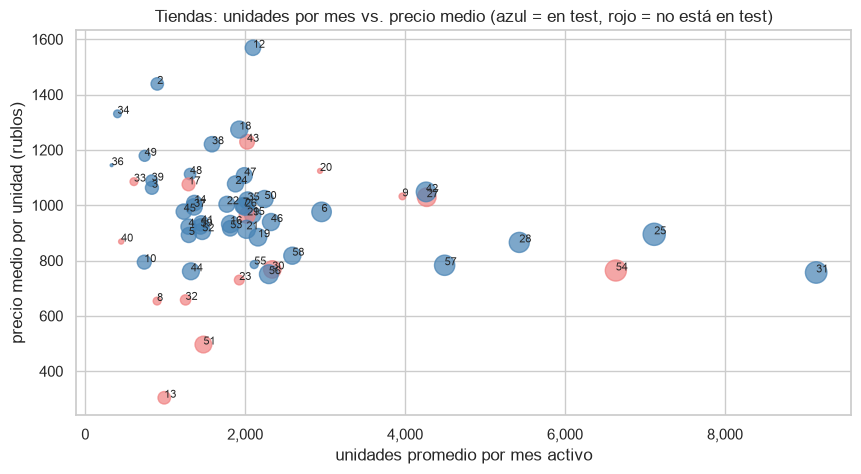

In [26]:
# Indicadores de desempeño por tienda
desempeno = sales.groupby("shop_id").agg(
    unidades=("item_cnt_day", "sum"),  # unidades totales
    ingresos=("revenue", "sum"),  # ingresos totales
    meses_activos=("date_block_num", "nunique"),  # meses con ventas
    productos=("item_id", "nunique"),  # surtido: productos distintos vendidos
)
desempeno["unidades_por_mes"] = desempeno["unidades"] / desempeno["meses_activos"]  # comparable entre tiendas
desempeno["precio_medio"] = desempeno["ingresos"] / desempeno["unidades"]  # ingreso promedio por unidad
desempeno["en_test"] = desempeno.index.isin(test["shop_id"])  # ¿hay que predecir esta tienda?
desempeno = desempeno.join(shops.set_index("shop_id")["shop_name"])  # nombre de la tienda
desempeno = desempeno.sort_values("unidades_por_mes", ascending=False)
display(desempeno)

# Dispersión: unidades por mes contra precio medio (tamaño = número de productos distintos)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(desempeno["unidades_por_mes"], desempeno["precio_medio"], s=desempeno["productos"] / 60,
           c=desempeno["en_test"].map({True: "steelblue", False: "lightcoral"}), alpha=0.7)
for sid, fila in desempeno.iterrows():  # etiqueta cada punto con su shop_id
    ax.annotate(str(sid), (fila["unidades_por_mes"], fila["precio_medio"]), fontsize=8)
ax.set(title="Tiendas: unidades por mes vs. precio medio (azul = en test, rojo = no está en test)",
       xlabel="unidades promedio por mes activo", ylabel="precio medio por unidad (rublos)")
ax.xaxis.set_major_formatter(MILES)
plt.show()

**Interpretación.**

- **Líderes:** la tienda **31** es la más grande, con unas 9,100 unidades por mes. Le siguen la 25, la 54, la 28 y la 57. La 54 ya no opera (vendió hasta el mes 27) y no está en `test`.
- **Tiendas atípicas por su forma de operar:**
  - la **9** ("Venta itinerante") y la **20** ("Moscú, liquidación") solo venden en meses puntuales: la 9 en octubre de cada año y en abril de 2015, y la 20 en octubre de 2014 y de 2015. Esto coincide con ferias y ventas especiales;
  - la **12** (tienda online) tiene el precio medio más alto (unos 1,570 rublos por unidad);
  - la **55** (almacén digital de 1C-Online) vende pocos productos distintos (unos 2,000), de tipo digital.
- **Precio medio:** la mayoría de las tiendas está entre 750 y 1,250 rublos por unidad. Las tiendas grandes tienen precios medios más bajos (unos 760-900), porque venden mucho volumen de productos baratos.
- **Tiendas cerradas:** varias tiendas que dejaron de operar (rojas en la gráfica) no se predicen. `test` incluye 42 tiendas, todas con historial.

## 27. Outliers y comportamientos anómalos por sucursal y producto (7c)

Se buscan anomalías en tres niveles:

1. **Transacciones**: precios y cantidades por encima del percentil 99.9 que siguen en los datos después de la limpieza.
2. **Productos**: productos cuyo precio varía de forma extrema (precio máximo más de 10 veces la mediana del mismo producto).
3. **Tiendas**: meses en que una tienda vende muy por encima o por debajo de lo habitual para ella (se usa la puntuación z robusta, con la mediana y la desviación absoluta mediana, que no se deja arrastrar por los propios outliers). También se identifican tiendas con un comportamiento distinto al resto: pocas semanas de actividad o tiendas no físicas (online, ventas en ruta).

Transacciones con precio > p99.9 (23,990): 2,931
Transacciones con cantidad > p99.9 (22): 2,881
Tiendas con más transacciones de cantidad > p99.9:
shop_id
31    502
25    316
12    288
54    232
28    200

Productos con precio máximo > 10 veces su mediana: 39


,median,max,count,max_sobre_mediana,item_name
item_id,,,,,
11857,0.10,729.00,154,"7,290.00",Змей ВАСЯ антистресс 36 см.
11865,0.10,729.00,197,"7,290.00",Змей МАКС антистресс 33 см.
11869,0.10,510.30,113,"5,103.00",Змей ЯШКА антистресс 33 см.
11864,0.10,469.00,129,"4,690.00",Змей ДЖЕККИ с сердечком 36 см
11859,0.10,379.00,104,"3,790.00",Змей ВАСЯ с цветком 33 см



Meses tienda con |z robusta| > 3.5: 37


,shop_id,date_block_num,unidades,z_robusta
23,2,23,"1,921.00",9.28
514,21,23,"3,959.00",9.14
984,40,23,"1,024.00",9.13
502,21,11,"3,623.00",7.65
1043,42,23,"7,256.00",7.25
1031,42,11,"6,988.00",6.65
1448,55,32,"6,867.00",6.01
1204,47,23,"3,679.00",5.99
1440,55,24,"6,429.00",5.51
841,34,23,658.00,5.38


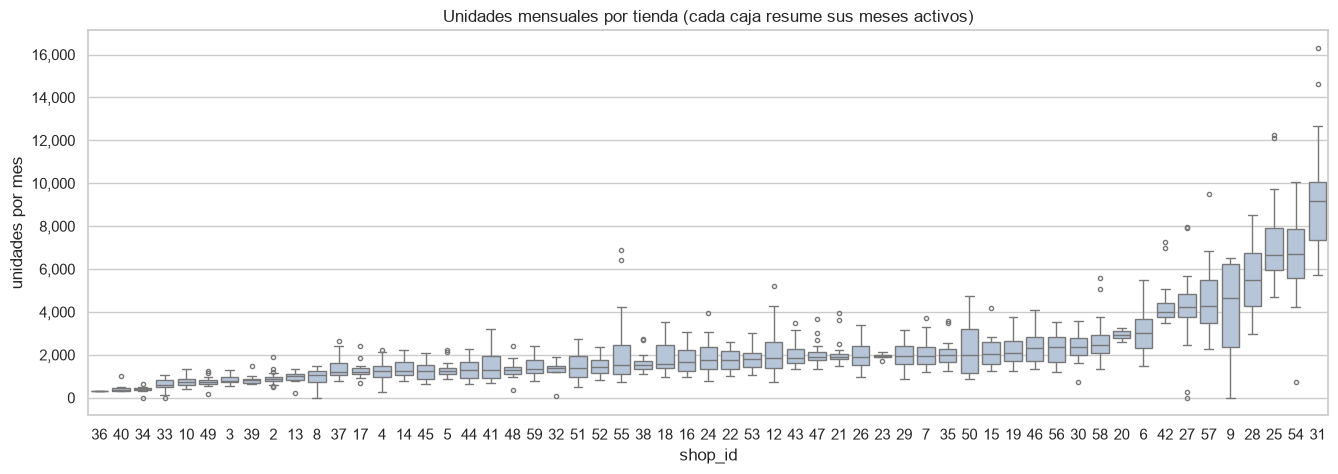

In [27]:
# 1) Transacciones por encima del percentil 99.9 que siguen en los datos
p999_precio = sales["item_price"].quantile(0.999)
p999_cant = sales["item_cnt_day"].quantile(0.999)
print(f"Transacciones con precio > p99.9 ({p999_precio:,.0f}): {(sales['item_price'] > p999_precio).sum():,}")
print(f"Transacciones con cantidad > p99.9 ({p999_cant:,.0f}): {(sales['item_cnt_day'] > p999_cant).sum():,}")
print("Tiendas con más transacciones de cantidad > p99.9:")
print(sales.loc[sales["item_cnt_day"] > p999_cant, "shop_id"].value_counts().head(5).to_string())

# 2) Productos con precio muy variable: máximo / mediana > 10
precio_prod = sales.groupby("item_id")["item_price"].agg(["median", "max", "count"])
precio_prod["max_sobre_mediana"] = precio_prod["max"] / precio_prod["median"]
variables = precio_prod[precio_prod["max_sobre_mediana"] > 10].sort_values("max_sobre_mediana", ascending=False)
print(f"\nProductos con precio máximo > 10 veces su mediana: {len(variables)}")
display(variables.head(5).join(items.set_index("item_id")["item_name"]))

# 3) Meses anómalos por tienda: z robusta = (valor - mediana) / (1.4826 * MAD)
tm = sales.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().rename("unidades").reset_index()
grupo = tm.groupby("shop_id")["unidades"]
mediana = grupo.transform("median")  # nivel habitual de cada tienda
mad = grupo.transform(lambda s: (s - s.median()).abs().median())  # dispersión robusta de cada tienda
tm["z_robusta"] = (tm["unidades"] - mediana) / (1.4826 * mad)
anomalos = tm[tm["z_robusta"].abs() > 3.5].sort_values("z_robusta", ascending=False)
print(f"\nMeses tienda con |z robusta| > 3.5: {len(anomalos)}")
display(anomalos.head(10))

# Diagrama de caja de las ventas mensuales por tienda (ordenadas por su mediana)
orden_tiendas = tm.groupby("shop_id")["unidades"].median().sort_values().index
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=tm, x="shop_id", y="unidades", order=orden_tiendas, color="lightsteelblue", fliersize=3, ax=ax)
ax.set(title="Unidades mensuales por tienda (cada caja resume sus meses activos)", xlabel="shop_id", ylabel="unidades por mes")
ax.yaxis.set_major_formatter(MILES)
plt.show()

**Interpretación.**

1. **Transacciones:** después de la limpieza quedan unas 2,900 transacciones por encima del p99.9 en precio y otras tantas en cantidad. Se concentran en las tiendas más grandes (31, 25, 54, 28) y en la online (12). Son ventas altas pero plausibles (consolas, lanzamientos, compras al por mayor), así que no se eliminan. Para el modelo, el efecto de las cantidades extremas se puede controlar recortando el target mensual (decisión de la fase 02).
2. **Productos con precio muy variable:** 39 productos tienen un precio máximo más de 10 veces su mediana. Los casos extremos son peluches ("Змей", serpiente antiestrés) con una mediana de **0.10 rublos**: se registraron ventas a precio casi simbólico, probablemente promociones o regalos. Son un riesgo si el precio se usa como variable.
3. **Meses anómalos por tienda:** hay 37 combinaciones tienda-mes con |z robusta| > 3.5. **26 de ellas son diciembres** (meses 11 y 23), es decir, la estacionalidad normal y no errores. Las demás son:
   - **meses bajos** al abrir o cerrar una tienda (13, 27, 32, 34 y 54 en su primer o último mes);
   - **meses altos** de las tiendas online (12) y digital (55), sobre todo septiembre de 2015 (mes 32), cuando se vendieron boletos para la feria "ИгроМир 2015".

En el diagrama de caja se ve que las tiendas grandes (31, 25, 54) tienen además la mayor dispersión mensual, y que tiendas como la 9 y la 27 tienen meses con ventas casi nulas, por apertura, cierre o actividad esporádica.

## 28. Visualización obligatoria: serie de tiempo de ventas totales (8a)

Serie mensual de las unidades totales vendidas por la cadena, con la línea de tendencia obtenida en la descomposición de la sección 22. Es la serie que se busca proyectar a noviembre de 2015.

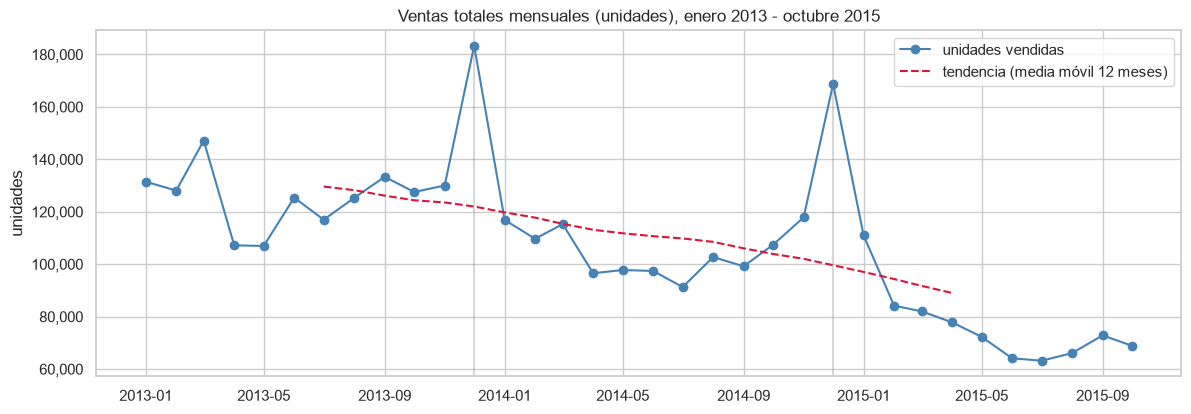

In [28]:
# Serie mensual de unidades con su tendencia
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(mensual.index, mensual["unidades"], marker="o", color="steelblue", label="unidades vendidas")
ax.plot(descomp.trend.index, descomp.trend, ls="--", color="crimson", label="tendencia (media móvil 12 meses)")
for fecha in mensual.index[mensual.index.month == 12]:  # marca los meses de diciembre
    ax.axvline(fecha, color="gray", alpha=0.3)
ax.set(title="Ventas totales mensuales (unidades), enero 2013 - octubre 2015", ylabel="unidades")
ax.yaxis.set_major_formatter(MILES)
ax.legend()
plt.show()

**Interpretación.** La serie total combina una **tendencia decreciente** (línea roja, de 130 mil a menos de 90 mil unidades al mes) con un **pico en cada diciembre** (líneas grises). El último dato, octubre de 2015, está en unas 69 mil unidades, cerca del mínimo histórico; noviembre de 2014 había vendido unas 118 mil. Para noviembre de 2015 cabe esperar un repunte estacional moderado sobre ese nivel bajo, no un regreso a los niveles de 2013.

## 29. Visualización obligatoria: ventas por sucursal (8b)

Barras con las unidades totales de cada tienda, de mayor a menor. Las barras rojas son tiendas que no están en `test.csv` (no hay que predecirlas). Los nombres de las tiendas están en la tabla de la sección 26.

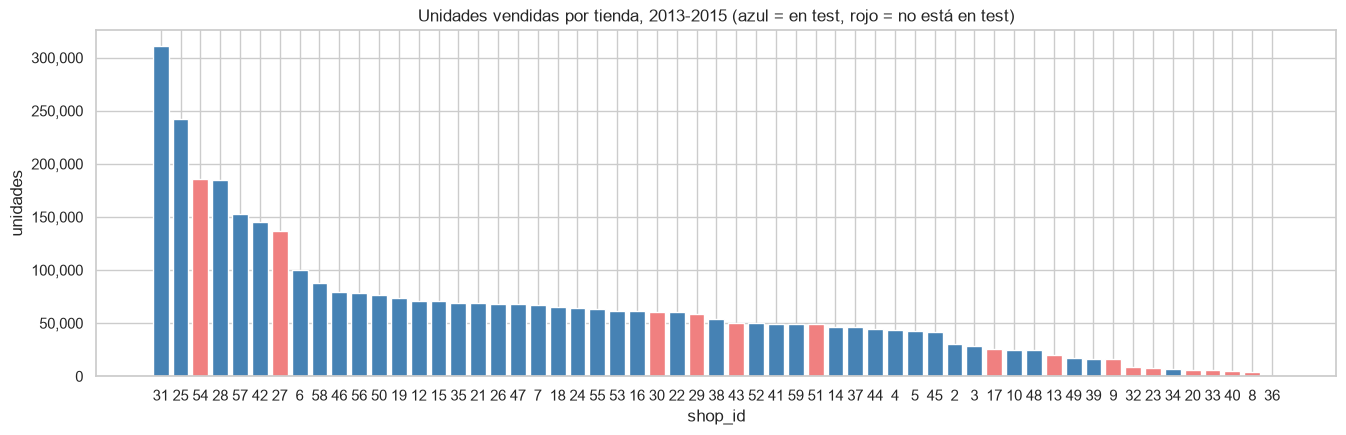

In [29]:
# Tiendas ordenadas por unidades totales
barras_tienda = desempeno.sort_values("unidades", ascending=False)
colores = barras_tienda["en_test"].map({True: "steelblue", False: "lightcoral"})  # azul: en test, rojo: no

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.bar(barras_tienda.index.astype(str), barras_tienda["unidades"], color=colores)
ax.set(title="Unidades vendidas por tienda, 2013-2015 (azul = en test, rojo = no está en test)", xlabel="shop_id", ylabel="unidades")
ax.yaxis.set_major_formatter(MILES)
plt.show()

**Interpretación.** El tamaño de las tiendas es muy desigual: la 31 vende más del doble que la quinta (57), y la mitad de las tiendas está por debajo de unas 54 mil unidades. Varias de las tiendas grandes en volumen histórico, como la 54 y la 27, ya cerraron y no están en `test`. Por eso el volumen histórico total no es buen indicador de las ventas futuras; importa más el nivel reciente.

## 30. Visualización obligatoria: ventas por producto (top N) y por categoría (8c)

- **Izquierda:** los N productos con más unidades vendidas (N se define en `pipeline_config.yaml`).
- **Derecha:** las unidades de todas las categorías con ventas, ordenadas de mayor a menor.

En los ejes se usan los IDs porque los nombres en ruso son largos; debajo de la gráfica se muestra la tabla con los nombres del top N.

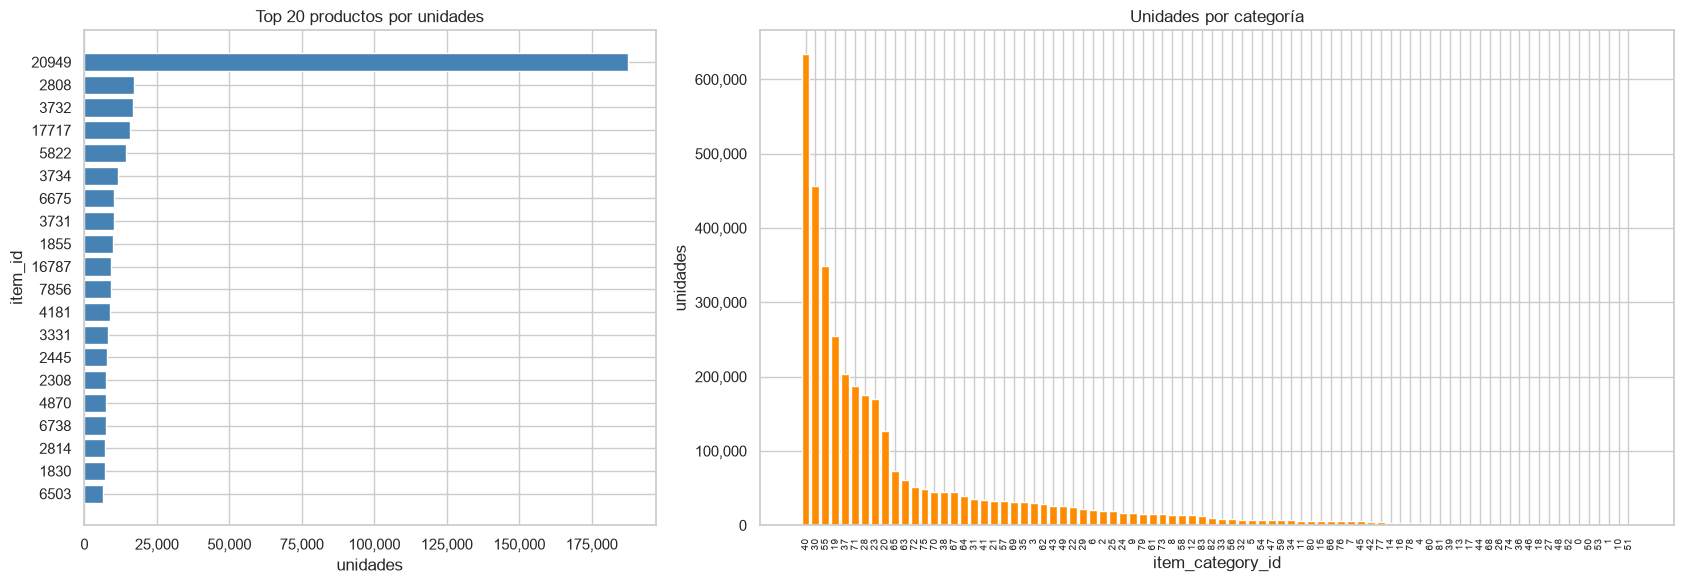

,item_name,item_category_id,item_category_name,unidades,ingresos
item_id,,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642.00","928,863.70"
2808,"Diablo III [PC, Jewel, русская версия]",30,Игры PC - Стандартные издания,"17,245.00","16,852,778.42"
3732,"Grand Theft Auto V [PS3, русские субтитры]",19,Игры - PS3,"16,642.00","43,617,975.49"
17717,Прием денежных средств для 1С-Онлайн,79,Служебные,"15,830.00","17,200,825.93"
5822,Playstation Store пополнение бумажника: Карта ...,35,Карты оплаты - PSN,"14,515.00","15,408,983.12"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",23,Игры - XBOX 360,"11,688.00","31,065,160.29"
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,12,Игровые консоли - PS4,"10,289.00","219,391,488.78"
3731,"Grand Theft Auto V [PC, русские субтитры]",30,Игры PC - Стандартные издания,"10,099.00","19,983,482.88"
1855,"Battlefield 4 [PC, русская версия]",30,Игры PC - Стандартные издания,"10,032.00","9,357,024.78"


In [30]:
TOP_N = CONFIG["eda"]["top_n_products"]  # cantidad de productos a mostrar
top_productos = tabla_prod.nlargest(TOP_N, "unidades")  # los N productos más vendidos
categorias_orden = tabla_cat.sort_values("unidades", ascending=False)  # categorías de mayor a menor

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(top_productos.index.astype(str)[::-1], top_productos["unidades"][::-1], color="steelblue")  # el mayor arriba
axes[0].set(title=f"Top {TOP_N} productos por unidades", xlabel="unidades", ylabel="item_id")
axes[0].xaxis.set_major_formatter(MILES)
axes[1].bar(categorias_orden.index.astype(str), categorias_orden["unidades"], color="darkorange")
axes[1].set(title="Unidades por categoría", xlabel="item_category_id", ylabel="unidades")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
axes[1].yaxis.set_major_formatter(MILES)
plt.tight_layout()
plt.show()

# Tabla de referencia con los nombres del top N
top_productos.join(nombre_categoria, on="item_category_id")[["item_name", "item_category_id", "item_category_name", "unidades", "ingresos"]]

**Interpretación.**

- **Productos:** la bolsa 20949 domina el top 20 con una diferencia enorme. El resto del ranking son casi solo **videojuegos** (sobre todo de PC, PS3 y Xbox 360), tarjetas de pago y suscripciones, además de una consola PS4. Los productos de mayor volumen son lanzamientos de franquicias conocidas.
- **Categorías:** la distribución es muy asimétrica. Cinco categorías (DVD, juegos de PC, CD de música, PS3 y Blu-Ray) superan las 200 mil unidades cada una, mientras que más de la mitad de las categorías tiene menos de 20 mil. Las categorías de la derecha casi no tienen ventas (libros, consolas antiguas, artículos especiales).

## 31. Visualización obligatoria: heatmaps de ventas en el tiempo por sucursal y por categoría (8d)

Cada celda muestra las unidades vendidas en un mes (columnas) por una tienda o una categoría (filas). El color permite ver de un vistazo cuándo abre o cierra cada tienda, qué categorías crecen o desaparecen y si el pico de diciembre afecta a todas por igual.

- **Arriba:** todas las tiendas, ordenadas por unidades totales.
- **Abajo:** las 20 categorías con más unidades.

Se usa escala logarítmica de color para que las tiendas y categorías pequeñas no queden todas del mismo color.

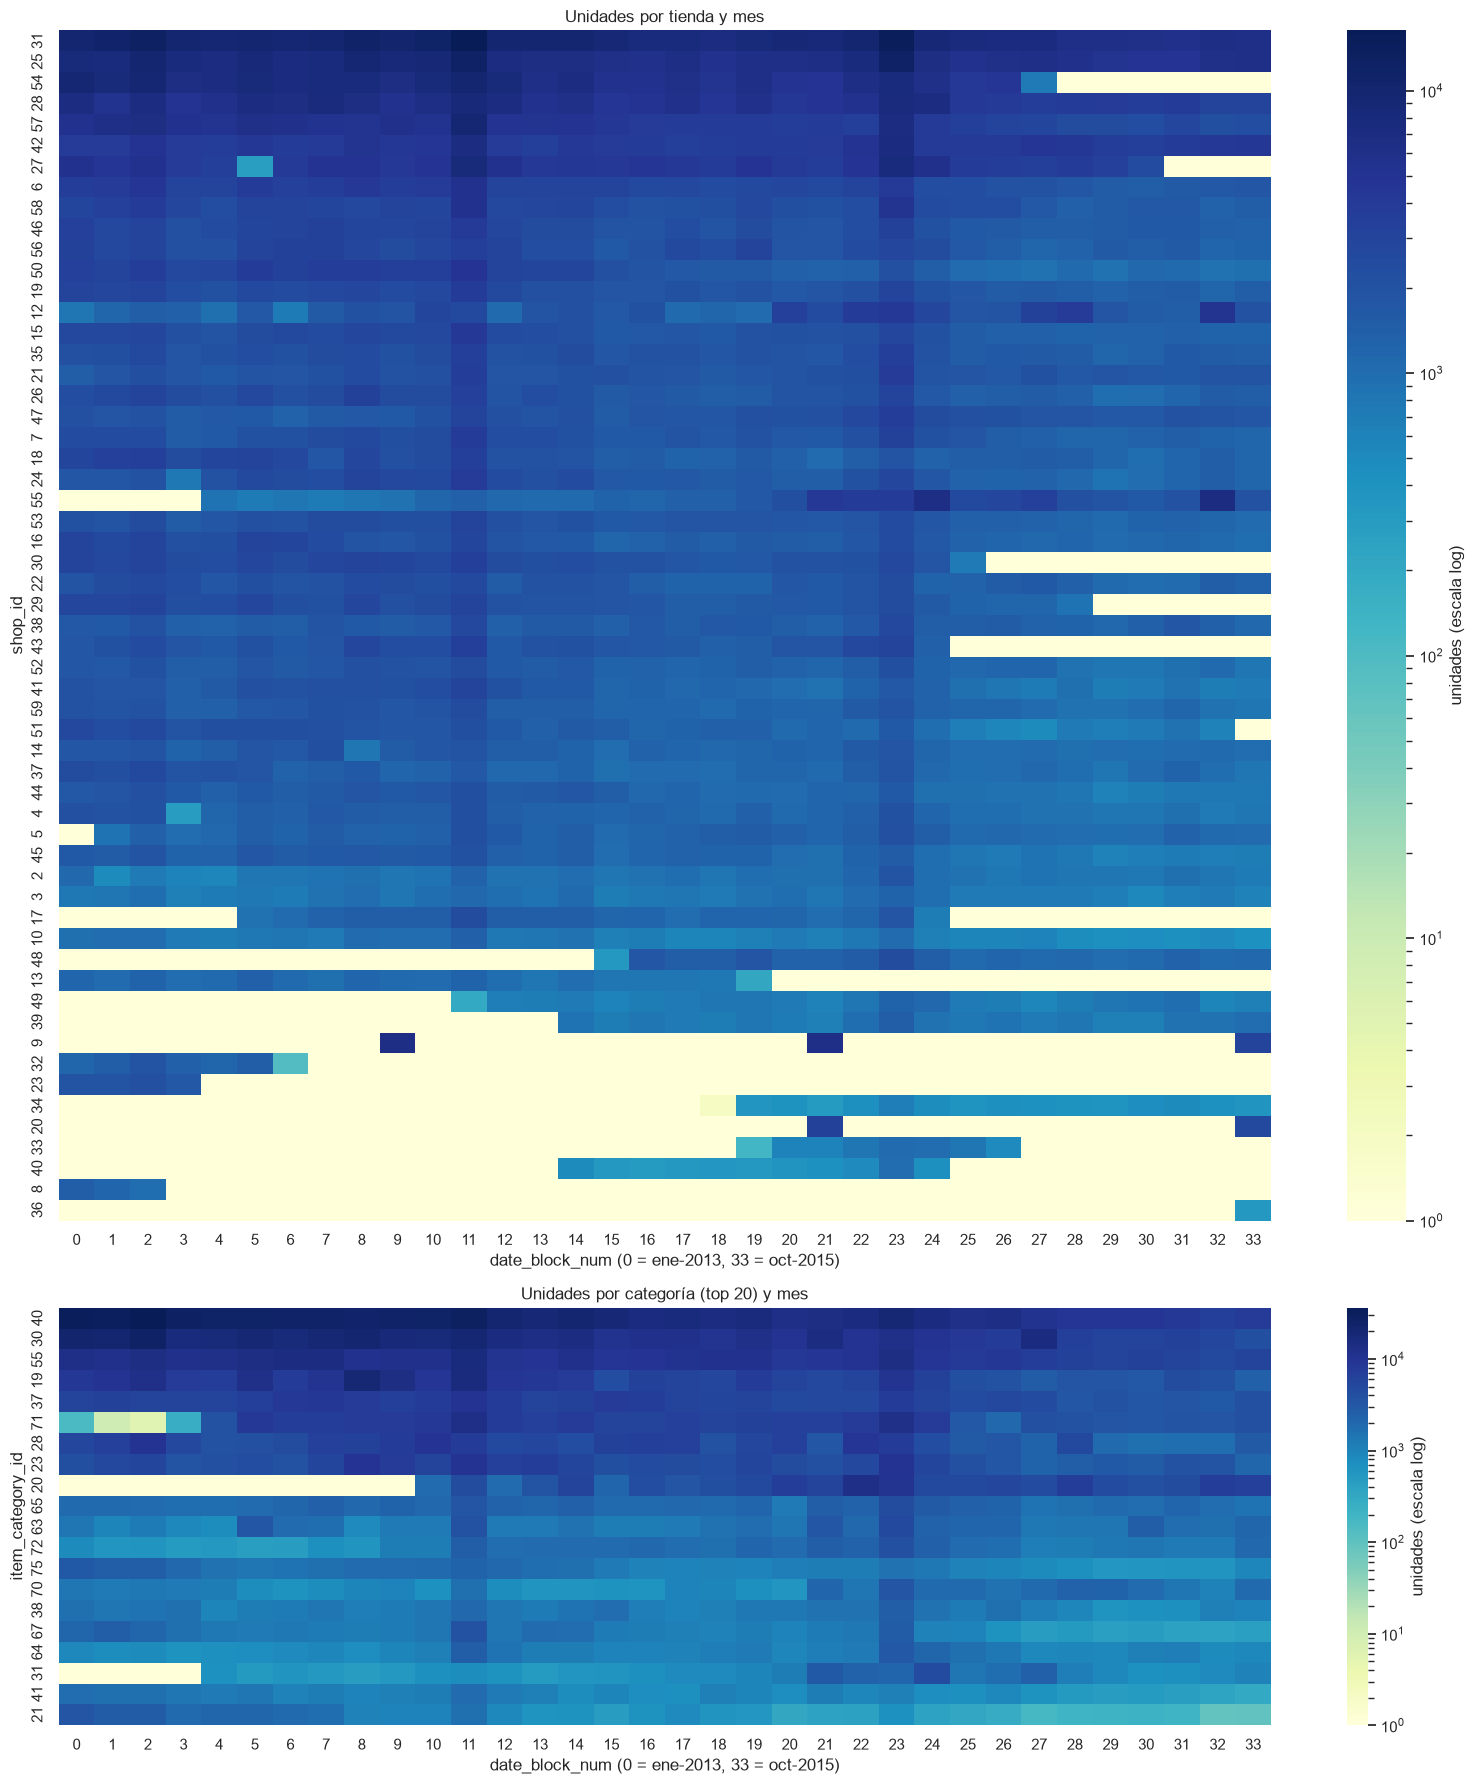

In [31]:
from matplotlib.colors import LogNorm  # escala de color logarítmica

# Matriz tienda x mes y categoría x mes (unidades), con 0 donde no hubo ventas
mat_tienda = sales.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
mat_tienda = mat_tienda.loc[mat_tienda.sum(axis=1).sort_values(ascending=False).index]  # ordenar filas por total
top_cats = tabla_cat.nlargest(20, "unidades").index  # 20 categorías principales
mat_cat = sales[sales["item_category_id"].isin(top_cats)].groupby(["item_category_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
mat_cat = mat_cat.loc[top_cats]  # mismo orden que el ranking

fig, axes = plt.subplots(2, 1, figsize=(16, 18), gridspec_kw={"height_ratios": [57, 20]})
for ax, mat, titulo, etiqueta in [(axes[0], mat_tienda, "Unidades por tienda y mes", "shop_id"),
                                  (axes[1], mat_cat, "Unidades por categoría (top 20) y mes", "item_category_id")]:
    sns.heatmap(mat.clip(lower=1), norm=LogNorm(), cmap="YlGnBu", ax=ax, cbar_kws={"label": "unidades (escala log)"})
    ax.set(title=titulo, xlabel="date_block_num (0 = ene-2013, 33 = oct-2015)", ylabel=etiqueta)
plt.tight_layout()
plt.show()

**Interpretación.**

- **Tiendas:** el heatmap muestra el **ciclo de vida** de cada tienda: tiendas que cierran (54, 27, 30, 29, 43, 17, 13, 32, 23, 8), tiendas que abren en el periodo (48, 49, 39, 34, 33) y tiendas esporádicas (9 y 20, con ventas casi solo en octubre). La tienda **36** solo tiene ventas en **octubre de 2015**, por lo que tendrá un único mes de historial. La columna 23 (diciembre de 2014) y la 11 (diciembre de 2013) se ven más oscuras en casi todas las tiendas: el pico de diciembre afecta a toda la cadena.
- **Categorías:** hay **cambios de mezcla**. La categoría **20 (juegos de PS4)** no existe hasta el mes 10 (noviembre de 2013, lanzamiento de la consola) y crece hasta ser una de las principales; su promedio mensual pasa de 541 unidades en 2013 a 5,422 en 2015. En cambio, las categorías tradicionales caen: DVD (40) de 27.6 mil a 10.2 mil unidades por mes, PS3 (19) de 11.2 mil a 3.8 mil y PC (30) de 19.6 mil a 7.5 mil. La categoría 71 (la bolsa) prácticamente no aparece en los primeros meses de 2013.

Por eso el modelo debe considerar el **momento del ciclo de vida** de cada tienda, categoría y producto, no solo su volumen promedio.

## 32. Selección de series para ACF y PACF (9)

La **ACF** (función de autocorrelación) mide cuánto se parece una serie a sí misma desplazada *k* periodos (rezagos). La **PACF** (autocorrelación parcial) mide esa relación directa con el rezago *k* quitando el efecto de los rezagos intermedios; ayuda a decidir cuántos términos autorregresivos (AR) usar.

Como hay 57 tiendas y más de 21,000 productos, se trabaja con una selección representativa definida en `pipeline_config.yaml`:

- **Criterio:** las 3 series con más unidades vendidas **entre las que aparecen en `test.csv`** (son las que hay que pronosticar).
- **Exclusiones** (para que las series representen demanda de productos reales):
  - el producto 20949 (bolsa de plástico de la marca), porque es un empaque que acompaña a otras compras;
  - las categorías de servicios 9 (entrega de mercancía) y 79 (servicios internos, como la recepción de pagos);
  - solo para los pares, las tiendas no físicas: 12 (tienda online), 55 (almacén digital), 9 (venta itinerante) y 20 (liquidación), cuyos pares más vendidos son envíos y licencias digitales.
- **Niveles:** ventas totales (mensual y diaria), por tienda, por producto y por par tienda-producto, agregadas a nivel mensual (34 observaciones). Los meses sin ventas se rellenan con 0.

Las bandas sombreadas de los gráficos son el intervalo de confianza del 95 %: una barra que sale de la banda indica una correlación estadísticamente significativa.

In [32]:
EDA = CONFIG["eda"]  # parámetros de esta sección
K = EDA["acf_top_k"]  # series por nivel
LAGS_M = EDA["acf_monthly_lags"]  # rezagos para series mensuales (< 34 / 2)
LAGS_D = EDA["acf_daily_lags"]  # rezagos para la serie diaria
EXCLUIR = EDA["acf_exclude_items"]  # productos excluidos de la selección
CATS_EXCLUIR = EDA["acf_exclude_categories"]  # categorías de servicios excluidas
TIENDAS_EXCLUIR = EDA["acf_pair_exclude_shops"]  # tiendas no físicas excluidas de los pares
pares_test = set(zip(test["shop_id"], test["item_id"]))  # pares que hay que predecir
MESES = range(34)  # date_block_num 0 a 33


def serie_mensual(df):
    # Suma unidades por mes y rellena con 0 los meses sin ventas para tener siempre 34 observaciones
    return df.groupby("date_block_num")["item_cnt_day"].sum().reindex(MESES, fill_value=0)


# Ranking de tiendas, productos y pares por unidades, restringido a lo que aparece en test
rk_tiendas = por_tienda[por_tienda.index.isin(test["shop_id"])]["unidades"].nlargest(K)
# Ventas de productos "reales": sin los productos excluidos ni las categorías de servicios
es_producto = ~sales["item_id"].isin(EXCLUIR) & ~sales["item_category_id"].isin(CATS_EXCLUIR)
por_prod_real = sales[es_producto].groupby("item_id")["item_cnt_day"].sum()
rk_productos = por_prod_real[por_prod_real.index.isin(test["item_id"])].nlargest(K)
# Pares: además se excluyen las tiendas no físicas
por_par = sales[es_producto & ~sales["shop_id"].isin(TIENDAS_EXCLUIR)].groupby(["shop_id", "item_id"])["item_cnt_day"].sum()
rk_pares = por_par[[p in pares_test for p in por_par.index]].nlargest(K)

# Diccionario {etiqueta: serie mensual} con todas las series seleccionadas
SERIES = {"Total cadena": serie_mensual(sales)}
SERIES.update({f"Tienda {s}": serie_mensual(sales[sales["shop_id"] == s]) for s in rk_tiendas.index})
SERIES.update({f"Producto {i}": serie_mensual(sales[sales["item_id"] == i]) for i in rk_productos.index})
SERIES.update({f"Par {s}-{i}": serie_mensual(sales[(sales["shop_id"] == s) & (sales["item_id"] == i)]) for s, i in rk_pares.index})

# Tabla descriptiva de las series elegidas
seleccion = pd.DataFrame({
    "unidades_totales": {k: v.sum() for k, v in SERIES.items()},
    "meses_con_ventas": {k: (v != 0).sum() for k, v in SERIES.items()},
})
nombres_sel = {f"Producto {i}": nombres[i] for i in rk_productos.index}  # nombres de productos elegidos
nombres_sel.update({f"Par {s}-{i}": nombres[i] for s, i in rk_pares.index})
seleccion["producto"] = pd.Series(nombres_sel)
seleccion

,unidades_totales,meses_con_ventas,producto
Total cadena,"3,646,036.00",34,NaN
Tienda 31,"310,777.00",34,NaN
Tienda 25,"241,920.00",34,NaN
Tienda 28,"184,557.00",34,NaN
Producto 2808,"17,245.00",34,"Diablo III [PC, Jewel, русская версия]"
Producto 3732,"16,642.00",26,"Grand Theft Auto V [PS3, русские субтитры]"
Producto 5822,"14,515.00",34,Playstation Store пополнение бумажника: Карта ...
Par 31-5822,"1,293.00",34,Playstation Store пополнение бумажника: Карта ...
Par 25-2808,"1,216.00",32,"Diablo III [PC, Jewel, русская версия]"
Par 31-3732,"1,142.00",25,"Grand Theft Auto V [PS3, русские субтитры]"


## 33. ACF y PACF de las ventas totales: serie mensual y diaria (9a)

- **Mensual**: 34 observaciones; se muestran hasta 16 rezagos, el máximo que admite la PACF (debe ser menor que la mitad de las observaciones).
- **Diaria**: 1,034 observaciones; se muestran 60 rezagos (unas 8 semanas) para detectar ciclos semanales.

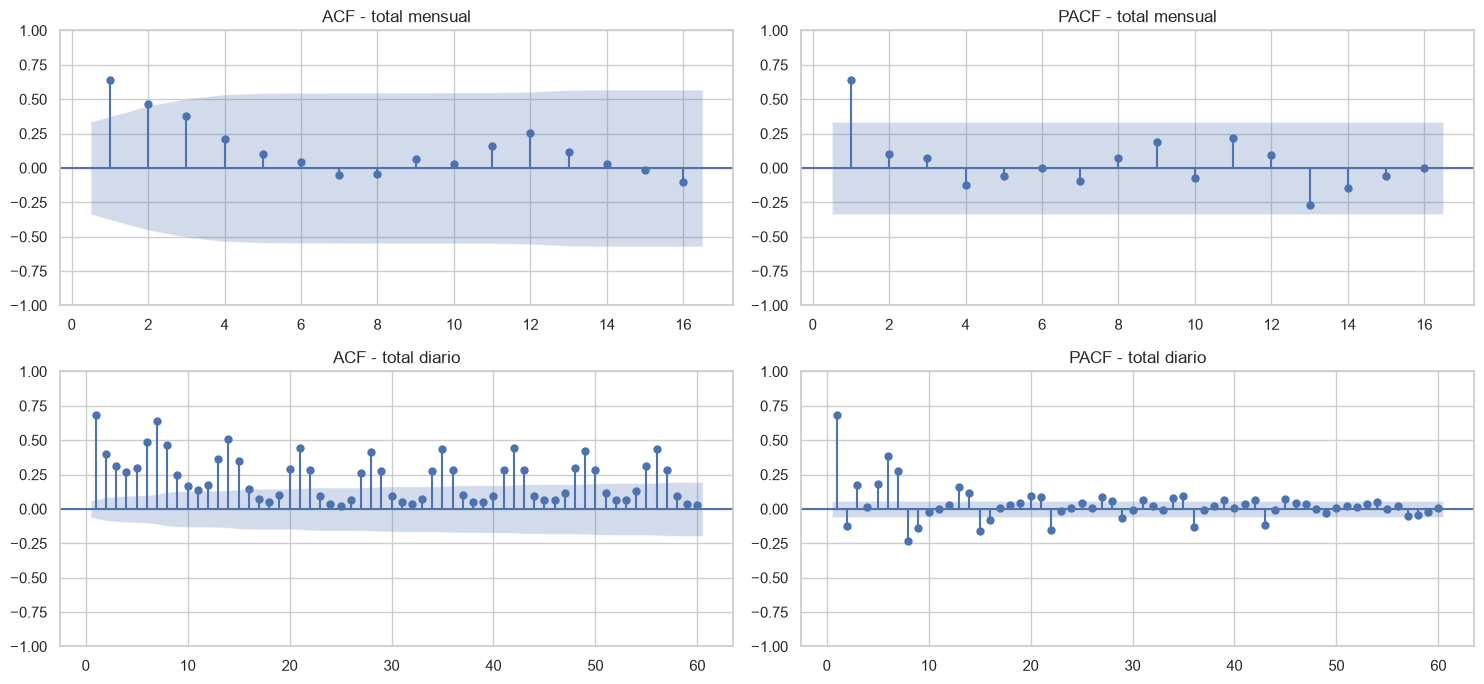

In [33]:
def graficar_acf_pacf(serie, titulo, lags, axes):
    # Dibuja la ACF en el primer eje y la PACF en el segundo, con intervalo de confianza del 95 %
    plot_acf(serie, lags=lags, ax=axes[0], title=f"ACF - {titulo}", zero=False)
    plot_pacf(serie, lags=lags, ax=axes[1], title=f"PACF - {titulo}", zero=False, method="ywm")


fig, axes = plt.subplots(2, 2, figsize=(15, 7))
graficar_acf_pacf(SERIES["Total cadena"], "total mensual", LAGS_M, axes[0])  # serie mensual
graficar_acf_pacf(por_dia, "total diario", LAGS_D, axes[1])  # serie diaria
plt.tight_layout()
plt.show()

## 34. ACF y PACF por sucursal (9a)

Series mensuales de las 3 tiendas con más unidades vendidas que aparecen en `test.csv`.

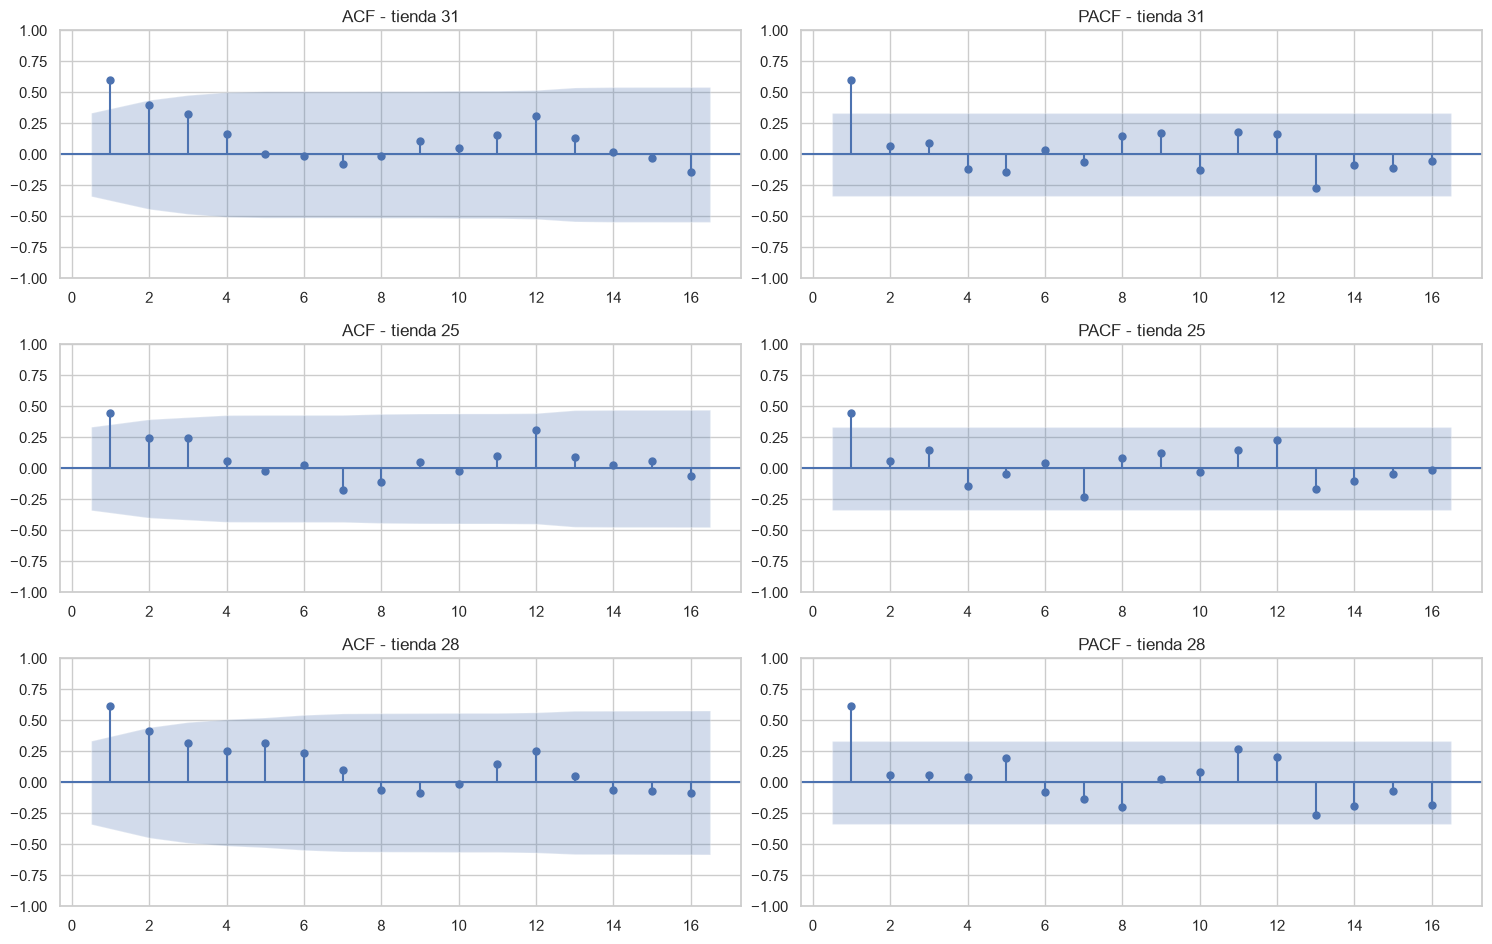

In [34]:
# Una fila de gráficos (ACF y PACF) por cada tienda seleccionada
fig, axes = plt.subplots(K, 2, figsize=(15, 3.2 * K))
for fila, s in zip(axes, rk_tiendas.index):
    graficar_acf_pacf(SERIES[f"Tienda {s}"], f"tienda {s}", LAGS_M, fila)
plt.tight_layout()
plt.show()

## 35. ACF y PACF por producto (9a)

Series mensuales de los 3 productos con más unidades vendidas que aparecen en `test.csv`, aplicando las exclusiones de la sección 32. Sus nombres están en la tabla de la sección 32.

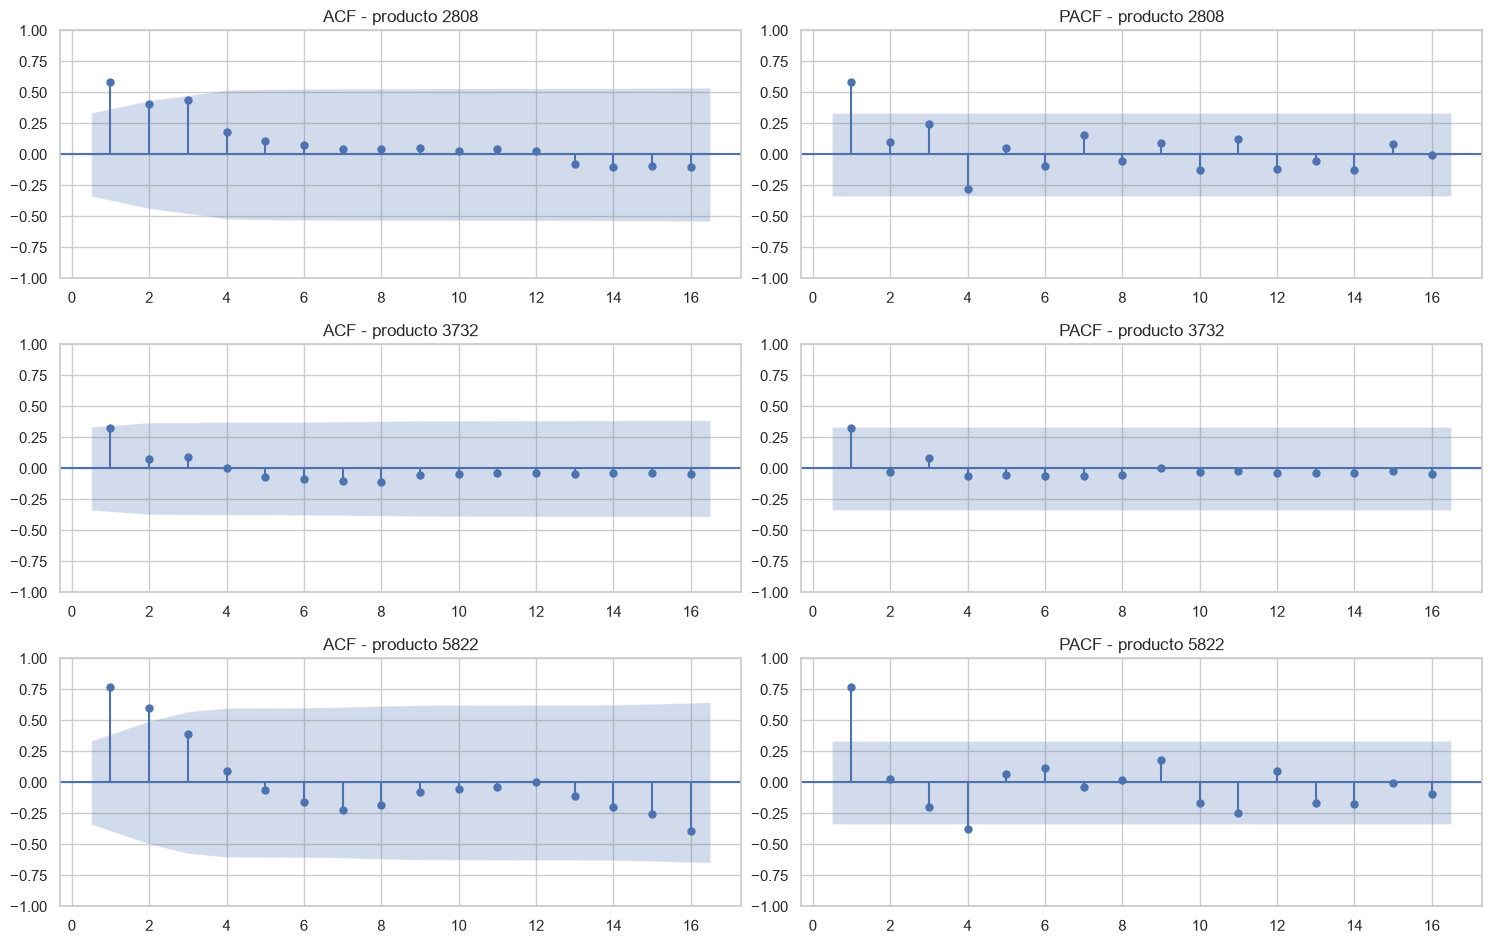

In [35]:
# Una fila de gráficos (ACF y PACF) por cada producto seleccionado
fig, axes = plt.subplots(K, 2, figsize=(15, 3.2 * K))
for fila, i in zip(axes, rk_productos.index):
    graficar_acf_pacf(SERIES[f"Producto {i}"], f"producto {i}", LAGS_M, fila)
plt.tight_layout()
plt.show()

## 36. ACF y PACF por par tienda-producto (9a)

Series mensuales de los 3 pares tienda-producto con más unidades vendidas que aparecen en `test.csv`, aplicando las exclusiones de la sección 32 (solo tiendas físicas).

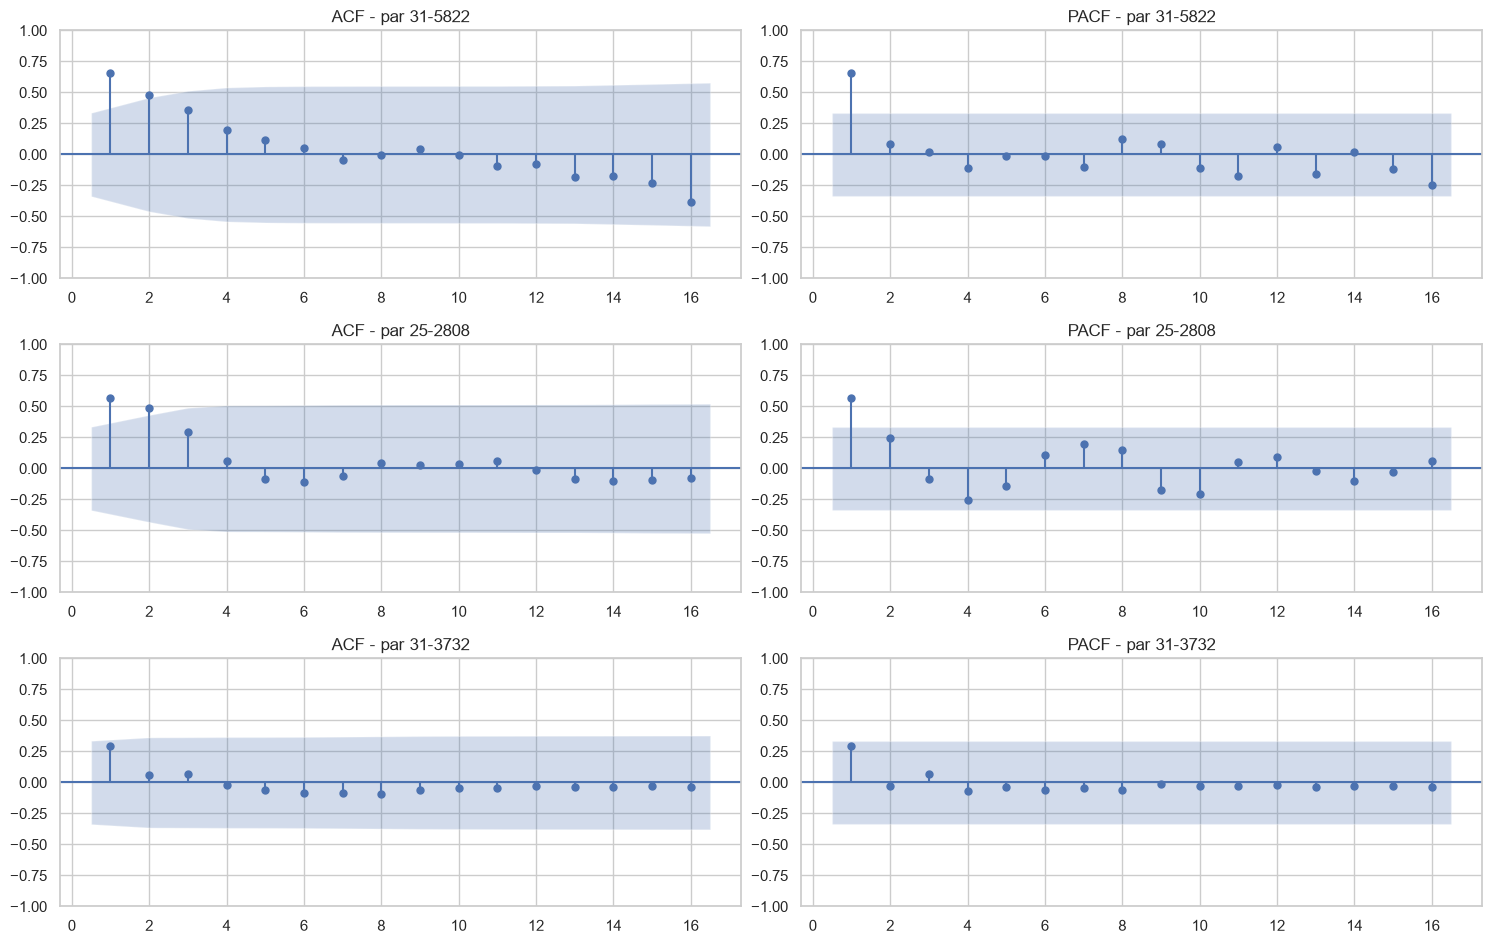

In [36]:
# Una fila de gráficos (ACF y PACF) por cada par seleccionado
fig, axes = plt.subplots(K, 2, figsize=(15, 3.2 * K))
for fila, (s, i) in zip(axes, rk_pares.index):
    graficar_acf_pacf(SERIES[f"Par {s}-{i}"], f"par {s}-{i}", LAGS_M, fila)
plt.tight_layout()
plt.show()

## 37. Resumen numérico de rezagos significativos (9b)

Para apoyar la interpretación de los gráficos, se listan los rezagos cuya ACF o PACF sale del intervalo de confianza del 95 %. Para la ACF se usa la banda de Bartlett (la misma que dibujan los gráficos) y para la PACF la banda ±1.96/√n.

In [37]:
def rezagos_significativos(serie, lags):
    # Devuelve los rezagos (sin el 0) donde la ACF y la PACF salen de la banda de confianza del 95 %
    valores_acf, ic_acf = acf(serie, nlags=lags, alpha=0.05, result_object=False)  # ACF e intervalos de Bartlett
    banda_acf = ic_acf[:, 1] - valores_acf  # semiancho de la banda en cada rezago
    valores_pacf = pacf(serie, nlags=lags, method="ywm")  # PACF
    banda_pacf = 1.96 / np.sqrt(len(serie))  # semiancho constante de la banda de la PACF
    sig_acf = [k for k in range(1, lags + 1) if abs(valores_acf[k]) > banda_acf[k]]
    sig_pacf = [k for k in range(1, lags + 1) if abs(valores_pacf[k]) > banda_pacf]
    return sig_acf, sig_pacf, valores_acf[1], valores_acf[12] if lags >= 12 else np.nan


# Aplica la función a todas las series mensuales y a la serie diaria total
filas = []
for etiqueta, serie in {**SERIES, "Total cadena (diaria)": por_dia}.items():
    lags = LAGS_D if "diaria" in etiqueta else LAGS_M
    sig_acf, sig_pacf, acf1, acf12 = rezagos_significativos(serie, lags)
    filas.append({"serie": etiqueta, "ACF_lag1": acf1, "ACF_lag12": acf12,
                  "rezagos_ACF_significativos": sig_acf, "rezagos_PACF_significativos": sig_pacf})
pd.DataFrame(filas).set_index("serie")

,ACF_lag1,ACF_lag12,rezagos_ACF_significativos,rezagos_PACF_significativos
serie,,,,
Total cadena,0.64,0.26,"[1, 2]",[1]
Tienda 31,0.60,0.31,[1],[1]
Tienda 25,0.44,0.31,[1],[1]
Tienda 28,0.61,0.25,[1],[1]
Producto 2808,0.58,0.03,[1],[1]
Producto 3732,0.32,-0.04,[],[]
Producto 5822,0.77,0.00,"[1, 2]","[1, 4]"
Par 31-5822,0.66,-0.08,"[1, 2]",[1]
Par 25-2808,0.57,-0.02,"[1, 2]",[1]


**Interpretación (9b).**

**i. ¿Existen correlaciones significativas a diferentes rezagos?**

- **Ventas totales mensuales:** la ACF es significativa en los rezagos 1 y 2 (0.64 y 0.47) y luego decae poco a poco, como corresponde a una serie con **tendencia**. La PACF solo es significativa en el **rezago 1**, lo que sugiere un componente **AR(1)**: el mejor predictor de un mes es el mes anterior.
- **Tiendas (31, 25, 28):** tienen el mismo patrón, con la ACF significativa en el rezago 1 (0.44-0.61) y la PACF solo en el rezago 1.
- **Productos y pares:**
  - Diablo III (2808) y la tarjeta PlayStation Store (5822), con sus pares (25-2808 y 31-5822), muestran una fuerte persistencia de corto plazo: ACF significativa en los rezagos 1 y 2 y PACF en el rezago 1. La 5822 tiene además un rezago 4 negativo en la PACF.
  - GTA V PS3 (3732) y su par 31-3732 **no tienen ningún rezago significativo**. Es un producto de lanzamiento: vende mucho en sus primeros meses y luego cae, así que su comportamiento depende más del **tiempo desde el lanzamiento** que de los meses anteriores.
- **Serie diaria total:** casi todos los rezagos son significativos y hay picos claros en los rezagos **7, 14, 21, 28…** (por ejemplo, 0.64 en el rezago 7). La PACF tiene valores significativos en los rezagos 1 y 6-8. Esto refleja el **ciclo semanal** de la sección 24.

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**

- **Mensual:** en la serie total y en las tiendas hay un repunte de la ACF en el **rezago 12** (0.25-0.31), el eco del pico de diciembre. **No llega a ser estadísticamente significativo**, porque con 34 observaciones la banda de confianza es muy ancha en rezagos altos. Aun así, la descomposición de la sección 22 confirma que la estacionalidad anual existe. En los productos y pares individuales el rezago 12 es casi 0: su ciclo de vida domina sobre la estacionalidad anual.
- **Diaria:** la estacionalidad **semanal** (periodo 7) es evidente y significativa.

**Implicación para el modelo:** las variables más útiles serán los **rezagos recientes** del target (1, 2 y 3 meses), el **mes del año** o un rezago de 12 meses para el pico de diciembre, y variables del **ciclo de vida** del producto (meses desde la primera venta).

## 38. Variables que afectan directamente las ventas (10a)

Se construye la tabla mensual tienda-producto (una fila por `shop_id`, `item_id` y `date_block_num` con ventas) y se mide qué tan relacionada está cada variable con el target `item_cnt_month`:

- Para **variables numéricas** se usa la correlación de Pearson **ρ** (de −1 a 1).
- Para **variables categóricas** se usa la **razón de correlación η** = √(SS_entre / SS_total), que va de 0 a 1 e indica qué parte de la variación del target se explica por los grupos de la variable.

Las variables evaluadas son: tienda, categoría, mes del año, mes consecutivo, precio promedio del mes y las ventas del mismo par en el mes anterior (rezago 1), que anticipa el tipo de variable que usará el modelo de forecasting. Se calcula sobre el target sin recortar; como `item_cnt_month` tiene cola larga, los valores son orientativos.

In [38]:
# Tabla mensual tienda-producto: target y precio promedio de cada mes
mensual_tp = sales.groupby(["date_block_num", "shop_id", "item_id"], as_index=False).agg(
    item_cnt_month=("item_cnt_day", "sum"), precio_medio=("item_price", "mean")
)
mensual_tp = mensual_tp.merge(items[["item_id", "item_category_id"]], on="item_id")  # categoría
mensual_tp["mes_del_anio"] = mensual_tp["date_block_num"] % 12 + 1  # 1 = enero ... 12 = diciembre

# Rezago 1: ventas del mismo par en el mes anterior (0 si no vendió)
anterior = mensual_tp[["date_block_num", "shop_id", "item_id", "item_cnt_month"]].copy()
anterior["date_block_num"] += 1  # se desplaza un mes hacia adelante para alinearlo con el mes siguiente
mensual_tp = mensual_tp.merge(anterior.rename(columns={"item_cnt_month": "ventas_mes_anterior"}),
                              on=["date_block_num", "shop_id", "item_id"], how="left")
mensual_tp["ventas_mes_anterior"] = mensual_tp["ventas_mes_anterior"].fillna(0)
mensual_tp = mensual_tp[mensual_tp["date_block_num"] > 0]  # el mes 0 no tiene mes anterior


def razon_correlacion(categorica, numerica):
    # eta = raíz de (variación entre grupos / variación total)
    media_global = numerica.mean()
    grupos = numerica.groupby(categorica)
    ss_entre = (grupos.size() * (grupos.mean() - media_global) ** 2).sum()  # variación explicada por los grupos
    ss_total = ((numerica - media_global) ** 2).sum()  # variación total
    return np.sqrt(ss_entre / ss_total)


y = mensual_tp["item_cnt_month"]  # target
relacion = pd.DataFrame([
    {"variable": "ventas_mes_anterior", "tipo": "numérica", "medida": "Pearson ρ", "valor": y.corr(mensual_tp["ventas_mes_anterior"])},
    {"variable": "precio_medio", "tipo": "numérica", "medida": "Pearson ρ", "valor": y.corr(mensual_tp["precio_medio"])},
    {"variable": "date_block_num", "tipo": "numérica (tiempo)", "medida": "Pearson ρ", "valor": y.corr(mensual_tp["date_block_num"])},
    {"variable": "item_category_id", "tipo": "categórica", "medida": "η", "valor": razon_correlacion(mensual_tp["item_category_id"], y)},
    {"variable": "shop_id", "tipo": "categórica", "medida": "η", "valor": razon_correlacion(mensual_tp["shop_id"], y)},
    {"variable": "mes_del_anio", "tipo": "categórica", "medida": "η", "valor": razon_correlacion(mensual_tp["mes_del_anio"], y)},
]).sort_values("valor", key=abs, ascending=False)
print(f"Filas de la tabla mensual tienda-producto: {len(mensual_tp):,}")
relacion

Filas de la tabla mensual tienda-producto: 1,545,899


,variable,tipo,medida,valor
0,ventas_mes_anterior,numérica,Pearson ρ,0.67
3,item_category_id,categórica,η,0.51
4,shop_id,categórica,η,0.07
5,mes_del_anio,categórica,η,0.03
1,precio_medio,numérica,Pearson ρ,0.03
2,date_block_num,numérica (tiempo),Pearson ρ,0.00


**Interpretación.** En orden de importancia:

- **`ventas_mes_anterior` (ρ = 0.67):** es, por mucho, la variable más relacionada con el target. Confirma lo visto en la ACF: las ventas de un par tienda-producto son persistentes de un mes a otro.
- **`item_category_id` (η = 0.51):** la categoría explica una parte grande de la variación. Algunas categorías venden muchas unidades por par (la bolsa, las tarjetas de pago, los juegos de lanzamiento) y otras casi siempre 1.
- **`shop_id` (η = 0.07) y `mes_del_anio` (η = 0.03):** tienen poco poder por sí solas a nivel de par. La tienda y el mes cambian sobre todo **cuántos pares** venden, más que cuánto vende cada par.
- **`precio_medio` (ρ = 0.03) y `date_block_num` (ρ = 0.00):** no tienen una relación lineal con el target. El precio actúa de forma no lineal y mezclado con la categoría, y la tendencia temporal afecta al total de la cadena (menos pares activos) más que a las ventas de cada par.

Estos coeficientes se calcularon solo sobre los pares que vendieron en cada mes y sin recortar el target, por lo que son orientativos. En la fase de features conviene recalcularlos sobre la cuadrícula completa (con ceros) y con el target recortado.

## 39. Cobertura de `test.csv` respecto del historial (10b)

Se mide cuánto historial tiene cada par a predecir:

- **Pares tienda-producto de test con historial**: el par vendió al menos una vez en train.
- **Productos de test que nunca aparecen en train**: productos nuevos, sin ninguna venta histórica en ninguna tienda.
- **Pares sin historial cuyo producto sí existe en train** (se vendió en otra tienda).

Además se revisa la estructura de `test.csv`: si es una cuadrícula completa de tiendas × productos.

In [39]:
# Conjuntos de pares, productos y tiendas vistos en train (con los IDs de tienda ya unificados)
pares_train = set(zip(sales["shop_id"], sales["item_id"]))
productos_train = set(sales["item_id"])
tiendas_train = set(sales["shop_id"])

# Clasificación de cada fila de test según su historial
cobertura = test.copy()
cobertura["par_con_historial"] = [p in pares_train for p in zip(cobertura["shop_id"], cobertura["item_id"])]
cobertura["producto_en_train"] = cobertura["item_id"].isin(productos_train)
cobertura["tienda_en_train"] = cobertura["shop_id"].isin(tiendas_train)

n = len(cobertura)  # filas de test
productos_test = cobertura["item_id"].nunique()
productos_nuevos = cobertura.loc[~cobertura["producto_en_train"], "item_id"].nunique()
print(f"Filas de test: {n:,} = {cobertura['shop_id'].nunique()} tiendas x {productos_test:,} productos "
      f"(cuadrícula completa: {n == cobertura['shop_id'].nunique() * productos_test})")
print(f"Pares con historial en train:           {cobertura['par_con_historial'].mean():.1%}")
print(f"Pares sin historial, producto conocido: {(~cobertura['par_con_historial'] & cobertura['producto_en_train']).mean():.1%}")
print(f"Pares de productos nuevos (sin ventas): {(~cobertura['producto_en_train']).mean():.1%}")
print(f"Productos de test que nunca aparecen en train: {productos_nuevos:,} de {productos_test:,} ({productos_nuevos / productos_test:.1%})")
print(f"Tiendas de test sin historial en train: {(~cobertura['tienda_en_train']).sum()}")

# Recencia: pares de test que vendieron en el último mes de train (octubre 2015)
pares_oct = set(zip(*sales.loc[sales["date_block_num"] == 33, ["shop_id", "item_id"]].values.T))
print(f"Pares de test con ventas en octubre 2015: {np.mean([p in pares_oct for p in zip(test['shop_id'], test['item_id'])]):.1%}")

Filas de test: 214,200 = 42 tiendas x 5,100 productos (cuadrícula completa: True)
Pares con historial en train:           52.0%
Pares sin historial, producto conocido: 40.8%
Pares de productos nuevos (sin ventas): 7.1%
Productos de test que nunca aparecen en train: 363 de 5,100 (7.1%)
Tiendas de test sin historial en train: 0
Pares de test con ventas en octubre 2015: 13.4%


**Interpretación.** `test.csv` es una **cuadrícula completa** de 42 tiendas × 5,100 productos (214,200 pares), no una lista de pares con historial. Por eso:

- solo el **52.0 %** de los pares de test tiene historial de ventas en train;
- el **40.8 %** son pares sin historial cuyo producto sí se vendió en otras tiendas;
- el **7.1 %** corresponde a **363 productos nuevos** (de 5,100) que nunca aparecen en train; la mayoría son películas en DVD (71), música en CD (38) y otras novedades;
- **todas** las tiendas de test tienen historial, aunque la 36 solo tiene un mes;
- apenas el **13.4 %** de los pares vendió en octubre de 2015.

**Consecuencia para el modelo:** la mayoría de los pares de test tendrá ventas **0** en noviembre. El modelo debe entrenarse sobre una **cuadrícula completa con ceros**, no solo sobre los pares con ventas. Para los productos nuevos hay que apoyarse en variables de **categoría** y de **tienda**, porque no hay rezagos propios.

## 40. Conclusiones del EDA (10)

### a. Variables que afectan directamente las ventas

1. **Historial reciente del par tienda-producto:** las ventas del mes anterior (ρ = 0.67) son el mejor predictor, y la ACF/PACF indica una estructura AR(1) a nivel total, tienda y producto.
2. **Categoría del producto:** η = 0.51. Define el nivel de ventas típico de un par y marca tendencias de mezcla, como el auge de PS4 y la caída de DVD y PS3.
3. **Calendario:** el pico de diciembre (cerca de +40 %) y la baja de primavera. A nivel diario hay un ciclo semanal con los sábados un 41 % sobre el promedio.
4. **Tendencia general decreciente:** el promedio mensual de la cadena cayó de 130 mil unidades (2013) a 76 mil (2015).
5. **Ciclo de vida:** apertura y cierre de tiendas, y lanzamientos de productos que venden mucho al principio y luego caen (por ejemplo, GTA V).
6. **Tienda:** el tamaño, el tipo (física, online o digital) y su estado (activa o cerrada).

### b. Patrones útiles para el modelo de forecasting

- **Agregar a frecuencia mensual** y construir una **cuadrícula completa** tienda × producto × mes con ceros, porque `test.csv` es una cuadrícula completa.
- **Variables de rezago** (1, 2, 3 y 12 meses) del target, y promedios históricos por tienda, producto y categoría, calculados **solo con meses anteriores**.
- **Variables de calendario:** mes del año (noviembre tiene un efecto estacional positivo moderado y precede al pico de diciembre) y número de días del mes.
- **Variables de novedad:** meses desde la primera venta del producto y de la tienda, y una indicadora de producto nuevo.
- **Cobertura de test:** solo el **52.0 %** de los pares tiene historial, el **40.8 %** son productos conocidos en una tienda nueva para ellos y el **7.1 %** son productos totalmente nuevos (363 de 5,100). Solo el 13.4 % de los pares vendió en el último mes, así que la predicción dominante será 0 o cercana a 0.
- **Distribución del target:** `item_cnt_month` tiene una cola muy larga. En los pares con ventas, la mediana es 1 y el 99 % vale 17 o menos. Conviene evaluar en la fase 02 el **recorte del target** (por ejemplo, a [0, 20], como en la competencia).

### c. Calidad y preparación del dataset

- **Calidad general alta:**
  - no hay valores nulos;
  - no hay días sin ventas;
  - `date_block_num` es totalmente consistente con la fecha;
  - los IDs de los catálogos son únicos.
- **Problemas detectados y resueltos** (decisiones en `pipeline_config.yaml`):
  - se unificaron 3 tiendas duplicadas (0→57, 1→58, 11→10);
  - se imputó 1 precio negativo con la mediana tienda-producto;
  - se eliminaron 2 outliers extremos;
  - se conservaron las devoluciones (0.25 % de las filas) y los 6 duplicados exactos.
- **Puntos de atención para las fases siguientes:**
  - productos con precios simbólicos (0.10 rublos);
  - tiendas no físicas (12, 55) y esporádicas (9, 20);
  - la tienda 36 con un solo mes de historial;
  - artículos que no son productos (la bolsa 20949 y los servicios de las categorías 9 y 79).

  Estos casos pueden necesitar un tratamiento especial en el modelo.
- **Preparación:** después de la limpieza, los datos están listos para la fase de preprocesamiento (notebook 02): construir la matriz mensual, recortar el target y crear los rezagos sin filtrar información del futuro.